# Actividad 4 — Análisis de base de datos transaccionales
## Segmentación de clientes y detección de anomalías con aprendizaje no supervisado

**Dataset:** *Online Retail* — tienda minorista online del Reino Unido, transacciones entre el **01/12/2010** y el **09/12/2011**. Gran parte de los clientes son **mayoristas**.

**Preguntas guía de la actividad:**

- **PG1.** ¿Se pueden segmentar los clientes de acuerdo con la cantidad de transacciones y el valor que gastan en la tienda?
- **PG2.** ¿Se pueden identificar transacciones anómalas en este registro?
- **PG3.** ¿Se pueden identificar clientes atípicos?

**Metodología (12 pasos):** carga y limpieza → serie de tiempo → reestructuración → EDA visual → *feature engineering* → detección de anomalías → escalamiento → PCA → elección de *k* → clustering → validación visual → interpretación de negocio.

> **Regla de trabajo:** el objetivo no es "correr K-Means", sino llegar a una **matriz donde cada fila sea un cliente** y cada columna una característica comparable de su comportamiento de compra.

---
# 1. Carga y limpieza

Antes de cualquier algoritmo hay que responder tres preguntas sobre los datos: **¿qué tipos tienen?**, **¿qué falta?** y **¿qué registros no representan una venta real?**

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

SEED = 42                      # reproducibilidad en todo el notebook
DATA = Path('data')            # carpeta 'data' junto al notebook
FIG = Path('fig'); FIG.mkdir(exist_ok=True)

### Estilo gráfico común

Se define una única paleta y un estilo para **todas** las figuras del notebook, de modo que el informe se lea como un solo sistema visual: colores diferenciables también para daltonismo, ejes y rejilla discretos, y etiquetas directas sobre los datos en lugar de leyendas cuando hay una sola serie.

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt

# Paleta categórica (orden fijo, nunca ciclado) y tintas
AZUL, NARANJA, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
AMARILLO, MAGENTA, VERDE = '#eda100', '#e87ba4', '#008300'
VIOLETA, ROJO = '#4a3aa7', '#e34948'
PALETA = [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO]
SUP, TINTA, TINTA2, TINTA3, REJILLA = '#fcfcfb', '#0b0b0b', '#52514e', '#8a8880', '#e6e5e1'

mpl.rcParams.update({
    'figure.facecolor': SUP, 'axes.facecolor': SUP, 'savefig.facecolor': SUP,
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'font.size': 10, 'text.color': TINTA,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlecolor': TINTA,
    'axes.titlelocation': 'left', 'axes.titlepad': 10,
    'axes.labelsize': 10, 'axes.labelcolor': TINTA2, 'axes.edgecolor': REJILLA,
    'axes.linewidth': 1.0, 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': TINTA2, 'ytick.color': TINTA2,
    'xtick.labelsize': 9, 'ytick.labelsize': 9,
    'grid.color': REJILLA, 'grid.linewidth': 1.0, 'axes.grid': False,
    'legend.frameon': False, 'legend.fontsize': 9,
    'lines.linewidth': 2.0, 'lines.markersize': 8,
})

def miles(v, dec=0):
    """Formato español: 1.234.567 y coma decimal."""
    return f'{v:,.{dec}f}'.replace(',', '·').replace('.', ',').replace('·', '.')

In [3]:
df_raw = pd.read_excel(DATA / 'data.xlsx')
print('Dimensiones:', df_raw.shape)
df_raw.head()

Dimensiones: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


## 1.1 Renombrado de columnas al español

Todo el análisis se trabaja con nombres en español para que las tablas y las gráficas del informe sean directamente legibles.

| Original | Español | Significado |
|---|---|---|
| `InvoiceNo` | `Factura` | Nº de factura; si empieza por "C" es una cancelación |
| `StockCode` | `CodProducto` | Código del artículo |
| `Description` | `Descripcion` | Nombre del artículo |
| `Quantity` | `Cantidad` | Unidades del artículo en esa transacción |
| `InvoiceDate` | `FechaHora` | Fecha y hora de la factura |
| `UnitPrice` | `PrecioUnitario` | Precio por unidad en libras esterlinas |
| `CustomerID` | `IdCliente` | Identificador del cliente |
| `Country` | `Pais` | País de residencia del cliente |

In [4]:
COLUMNAS_ES = {
    'InvoiceNo':   'Factura',
    'StockCode':   'CodProducto',
    'Description': 'Descripcion',
    'Quantity':    'Cantidad',
    'InvoiceDate': 'FechaHora',
    'UnitPrice':   'PrecioUnitario',
    'CustomerID':  'IdCliente',
    'Country':     'Pais',
}

df = df_raw.rename(columns=COLUMNAS_ES)
COLS_ORIG = list(df.columns)          # las 8 columnas originales, ya en español
df.head(3)

,Factura,CodProducto,Descripcion,Cantidad,FechaHora,PrecioUnitario,IdCliente,Pais
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom


## 1.2 Auditoría del dataset crudo

Revisamos tipos, faltantes y cardinalidad de cada columna.

In [5]:
auditoria = pd.DataFrame({
    'Tipo': df.dtypes.astype(str),
    'Nulos': df.isna().sum(),
    '% Nulos': (100 * df.isna().mean()).round(2),
    'Únicos': df.nunique(),
})
auditoria

,Tipo,Nulos,% Nulos,Únicos
Factura,object,0,0.00,25900
CodProducto,object,0,0.00,4070
Descripcion,object,1454,0.27,4223
Cantidad,int64,0,0.00,722
FechaHora,datetime64[us],0,0.00,23260
PrecioUnitario,float64,0,0.00,1630
IdCliente,float64,135080,24.93,4372
Pais,str,0,0.00,38


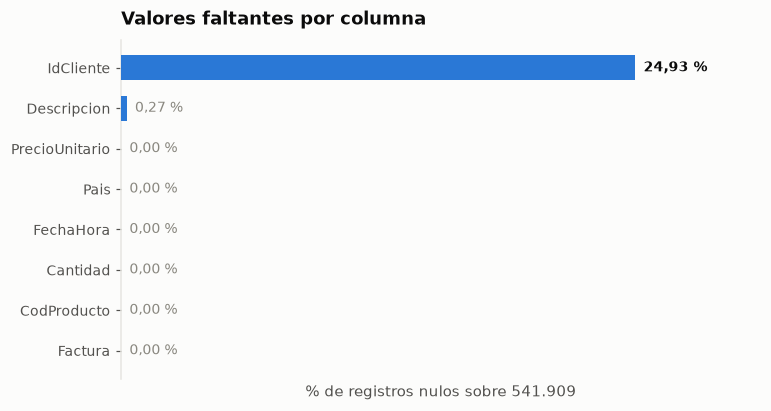

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 4))
nulos = (100 * df.isna().mean()).sort_values()

ax.barh(range(len(nulos)), nulos.values, height=0.62, color=AZUL, zorder=3)
for i, v in enumerate(nulos.values):
    ax.text(v + 0.4, i, f'{miles(v, 2)} %', va='center', fontsize=9,
            color=TINTA if v > 1 else TINTA3, fontweight='bold' if v > 1 else 'normal')
ax.set_yticks(range(len(nulos)), nulos.index)
ax.set_xlim(0, 31); ax.set_xticks([])
ax.spines['bottom'].set_visible(False)
ax.set_title('Valores faltantes por columna')
ax.set_xlabel('% de registros nulos sobre 541.909')
fig.savefig(FIG / 'e1_faltantes.png'); plt.show()

**Lectura de la gráfica:** los faltantes están concentrados en **una sola columna**. `IdCliente` falta en uno de cada cuatro registros; `Descripcion` apenas en el 0,27 %; las otras seis columnas están completas. No es un problema repartido por todo el dataset, es un problema puntual y muy grande.

In [7]:
df.describe()

,Cantidad,FechaHora,PrecioUnitario,IdCliente
count,"541,909.00",541909,"541,909.00","406,829.00"
mean,9.55,2011-07-04 13:34:57.156386,4.61,"15,287.69"
min,"-80,995.00",2010-12-01 08:26:00,"-11,062.06","12,346.00"
25%,1.00,2011-03-28 11:34:00,1.25,"13,953.00"
50%,3.00,2011-07-19 17:17:00,2.08,"15,152.00"
75%,10.00,2011-10-19 11:27:00,4.13,"16,791.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,218.08,NaN,96.76,"1,713.60"


**Lectura:**

- **`IdCliente` tiene un 24,9 % de faltantes.** Es el problema de calidad más grave: sin identificador no se puede agrupar por cliente.
- `Cantidad` va de **−80.995 a 80.995** y `PrecioUnitario` llega a **£38.970**, con mínimo negativo. Hay devoluciones y asientos contables mezclados con ventas.
- `Descripcion` tiene 1.454 nulos (0,27 %) — más adelante veremos que no es un problema independiente.

## 1.3 Banderas: cancelaciones y códigos que no son productos

Dos marcas que se crean **antes** de borrar nada, porque ambas son información valiosa:

1. **Cancelaciones**: la guía del dataset indica que una `Factura` que empieza con **"C"** es una cancelación. No se eliminan: se marcan para poder calcular el gasto **neto** y la **tasa de devolución** de cada cliente.
2. **Códigos que no son artículos**: portes (`POST`, `DOT`, `C2`), ajustes manuales (`M`), descuentos (`D`), muestras (`S`), comisiones (`BANK CHARGES`, `AMAZONFEE`, `CRUK`), deuda incobrable (`B`) y vales de regalo (`gift_0001_*`). Son cargos administrativos: si se dejan, inflan el gasto y contaminan la detección de anomalías.

In [8]:
df['Factura'] = df['Factura'].astype(str)
df['CodProducto'] = df['CodProducto'].astype(str)

# 1) Cancelaciones
df['EsCancelacion'] = df['Factura'].str.upper().str.startswith('C')

# 2) Códigos que no corresponden a un artículo
NO_PRODUCTO = {'POST', 'DOT', 'C2', 'M', 'BANK CHARGES', 'AMAZONFEE',
               'CRUK', 'S', 'D', 'B', 'PADS'}
cod = df['CodProducto'].str.upper()
df['EsProducto'] = ~(cod.isin(NO_PRODUCTO) | cod.str.startswith('GIFT_'))

# 3) Valor de la línea de factura
df['ValorTotal'] = df['Cantidad'] * df['PrecioUnitario']

n_fact_canc = df.loc[df['EsCancelacion'], 'Factura'].nunique()
print('Filas de cancelación :', df['EsCancelacion'].sum())
print('Facturas canceladas  :', n_fact_canc,
      f"({100 * n_fact_canc / df['Factura'].nunique():.1f}% de las facturas)")
print('Filas no-producto    :', (~df['EsProducto']).sum())

Filas de cancelación : 9288
Facturas canceladas  : 3836 (14.8% de las facturas)
Filas no-producto    : 2950


In [9]:
# ¿Qué hay exactamente en los códigos que no son artículos?
(df.loc[~df['EsProducto']]
   .groupby('CodProducto')
   .agg(Registros=('Cantidad', 'size'),
        Descripcion=('Descripcion', 'first'),
        PrecioMediano=('PrecioUnitario', 'median'))
   .sort_values('Registros', ascending=False)
   .head(12))

,Registros,Descripcion,PrecioMediano
CodProducto,,,
POST,1256,POSTAGE,18.00
DOT,710,DOTCOM POSTAGE,184.94
M,571,Manual,7.95
C2,144,CARRIAGE,50.00
D,77,Discount,22.97
S,63,SAMPLES,19.50
BANK CHARGES,37,Bank Charges,82.73
AMAZONFEE,34,AMAZON FEE,"5,909.88"
CRUK,16,CRUK Commission,471.77


## 1.4 Duplicados exactos

Filas idénticas en las 8 columnas originales: misma factura, mismo producto, misma cantidad, mismo precio y misma marca de tiempo. No son una venta adicional, son un registro repetido.

In [10]:
n_dup = df.duplicated(subset=COLS_ORIG).sum()
df = df.drop_duplicates(subset=COLS_ORIG).reset_index(drop=True)
print(f'Duplicados eliminados: {n_dup:,}  →  filas restantes: {len(df):,}')

Duplicados eliminados: 5,268  →  filas restantes: 536,641


## 1.5 Variables derivadas

Las variables de calendario permitirán el análisis temporal del paso 2.

In [11]:
df['Fecha']     = df['FechaHora'].dt.normalize()
df['Mes']       = df['FechaHora'].dt.to_period('M').astype(str)
df['DiaSemana'] = df['FechaHora'].dt.dayofweek      # 0 = lunes
df['Hora']      = df['FechaHora'].dt.hour

df[['Factura', 'CodProducto', 'Cantidad', 'PrecioUnitario', 'ValorTotal',
    'EsCancelacion', 'EsProducto', 'Hora']].head()

,Factura,CodProducto,Cantidad,PrecioUnitario,ValorTotal,EsCancelacion,EsProducto,Hora
0,536365,85123A,6,2.55,15.30,False,True,8
1,536365,71053,6,3.39,20.34,False,True,8
2,536365,84406B,8,2.75,22.00,False,True,8
3,536365,84029G,6,3.39,20.34,False,True,8
4,536365,84029E,6,3.39,20.34,False,True,8


## 1.6 ¿Las cancelaciones son un caso aislado o un comportamiento estable?

Antes de decidir qué hacer con ellas conviene verlo en el tiempo: si fueran un incidente puntual bastaría con aislarlas, pero si son un patrón permanente hay que modelarlas.

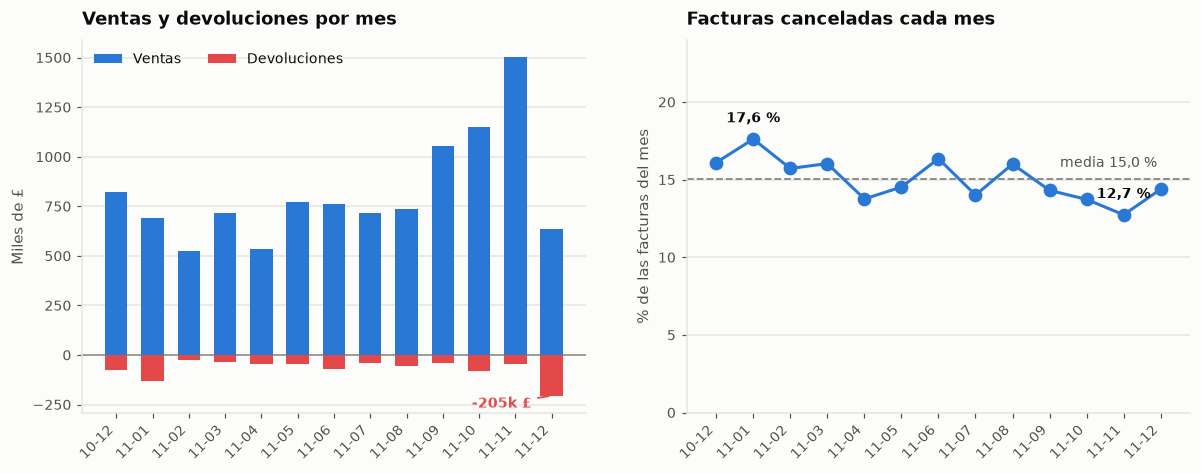

In [12]:
# Agregado mensual de ventas, devoluciones y facturas
mensual = (df.groupby(df['FechaHora'].dt.to_period('M').astype(str))
             .apply(lambda g: pd.Series({
                 'Ventas': g.loc[~g['EsCancelacion'], 'ValorTotal'].sum(),
                 'Devoluciones': g.loc[g['EsCancelacion'], 'ValorTotal'].sum(),
                 'FactTotal': g['Factura'].nunique(),
                 'FactCanc': g.loc[g['EsCancelacion'], 'Factura'].nunique()})))
mensual['PctCanc'] = 100 * mensual['FactCanc'] / mensual['FactTotal']

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
x = np.arange(len(mensual))
etiq = [m[2:] for m in mensual.index]

ax = axes[0]
ax.bar(x, mensual['Ventas'] / 1000, color=AZUL, width=0.62, zorder=3, label='Ventas')
ax.bar(x, mensual['Devoluciones'] / 1000, color=ROJO, width=0.62, zorder=3, label='Devoluciones')
ax.axhline(0, color=TINTA3, lw=1)
ax.set_xticks(x, etiq, rotation=45, ha='right')
ax.grid(axis='y', zorder=0)
ax.set_title('Ventas y devoluciones por mes')
ax.set_ylabel('Miles de £')
ax.legend(loc='upper left', ncol=2)
peor = int(np.argmin(mensual['Devoluciones'].values))
ax.annotate(f"{miles(mensual['Devoluciones'].iloc[peor] / 1000)}k £",
            xy=(peor, mensual['Devoluciones'].iloc[peor] / 1000),
            xytext=(peor - 2.2, mensual['Devoluciones'].iloc[peor] / 1000 - 60),
            fontsize=9, color=ROJO, fontweight='bold',
            arrowprops=dict(arrowstyle='-', color=ROJO, lw=1.2))

ax = axes[1]
media = mensual['PctCanc'].mean()
ax.axhline(media, color=TINTA3, ls='--', lw=1.2, zorder=2)
ax.plot(x, mensual['PctCanc'], color=AZUL, marker='o', zorder=3)
ax.set_xticks(x, etiq, rotation=45, ha='right')
ax.set_xlim(-0.8, len(x) - 0.2); ax.set_ylim(0, 24)
ax.grid(axis='y', zorder=0)
ax.set_title('Facturas canceladas cada mes')
ax.set_ylabel('% de las facturas del mes')
for xi, v in zip(x, mensual['PctCanc']):
    if v in (mensual['PctCanc'].max(), mensual['PctCanc'].min()):
        ax.annotate(f'{miles(v, 1)} %', (xi, v), textcoords='offset points',
                    xytext=(0, 11), ha='center', fontsize=9, color=TINTA, fontweight='bold')
ax.text(len(x) - 1.1, media + 0.8, f'media {miles(media, 1)} %',
        fontsize=9, color=TINTA2, ha='right')

fig.savefig(FIG / 'e1_cancelaciones.png'); plt.show()

**Lectura de la gráfica:** las cancelaciones **no son un incidente puntual**. Todos los meses se cancela entre el **12,7 % y el 17,6 %** de las facturas, con una media del **15,0 %** y sin tendencia a la baja. En libras el impacto es irregular: diciembre de 2011 concentra **−205.000 £** en devoluciones sobre solo 638.000 £ vendidos, un mes en el que se devuelve casi un tercio de lo facturado.

Conclusión operativa: **cancelar es parte del comportamiento normal de estos clientes** — coherente con una base mayorista que ajusta pedidos grandes. Por eso no se eliminan: se convierten en la variable `tasa_cancelacion` del paso 5, y las transacciones de devolución extremas serán candidatas naturales en la detección de anomalías (**PG2**).

## 1.7 Tratamiento de los faltantes

La pregunta correcta no es *"¿cómo relleno el NaN?"* sino **"¿el NaN es un error o significa algo?"**. Revisemos si los faltantes de `Descripcion` son un problema independiente o si coinciden con otros.

In [13]:
mask = df['Descripcion'].isna()
print('Descripcion nula        :', mask.sum())
print('… y además sin IdCliente:', (mask & df['IdCliente'].isna()).sum())
print('… y además Precio = 0   :', (mask & (df['PrecioUnitario'] == 0)).sum())

Descripcion nula        : 1454
… y además sin IdCliente: 1454
… y además Precio = 0   : 1454


**Hallazgo:** el solapamiento es del **100 %**. Los 1.454 registros sin descripción son exactamente los mismos que no tienen cliente y tienen precio cero: se trata de **asientos técnicos sin valor comercial**, no de un problema de calidad separado. Quedan resueltos por las reglas siguientes, sin necesidad de imputar nada.

Para `IdCliente` el faltante es un **bloque masivo (≈25 %)** que no se puede imputar: no existe forma de adivinar a qué cliente pertenece una factura anónima. La decisión es **separar el trabajo en dos datasets** en lugar de perder ese 25 % de información.

## 1.8 Los dos datasets de trabajo

| | **A · Transacciones** | **B · Base cliente** |
|---|---|---|
| Contenido | Todo lo depurado de duplicados | Solo artículos, con cliente y precio > 0 |
| Uso | EDA temporal y de negocio (pasos 2–4), anomalías por transacción (**PG2**) | Matriz de clientes (paso 5), anomalías por cliente (**PG3**) y clustering |

Las **cancelaciones se conservan en ambos**: son necesarias para el gasto neto y la tasa de devolución.

In [14]:
bitacora = []

def registrar(paso, afectadas, restantes, motivo):
    bitacora.append({'Paso': paso, 'Filas afectadas': afectadas,
                     'Filas restantes': restantes, 'Decisión': motivo})

registrar('0. Carga cruda', len(df_raw), len(df_raw), 'Dataset original')
registrar('1. Duplicados exactos', -n_dup, len(df),
          'Registro repetido, no venta adicional')

# --- Dataset A: nivel transacción -----------------------------------------
df_trans = df.copy()

# --- Dataset B: base para el nivel cliente --------------------------------
base = df_trans.copy()

n = (~base['EsProducto']).sum()
base = base[base['EsProducto']]
registrar('2. Códigos no-producto', -n, len(base),
          'Portes, comisiones, descuentos y vales: no son artículos')

n = base['IdCliente'].isna().sum()
base = base[base['IdCliente'].notna()]
registrar('3. Sin IdCliente', -n, len(base),
          'Imposible agrupar sin ID; se excluyen SOLO del nivel cliente')

n = (base['PrecioUnitario'] <= 0).sum()
base = base[base['PrecioUnitario'] > 0]
registrar('4. PrecioUnitario <= 0', -n, len(base),
          'Precio 0 = muestra; negativo = asiento contable')

registrar('5. Cancelaciones', int(base['EsCancelacion'].sum()), len(base),
          'NO se eliminan: se marcan para gasto neto y tasa de cancelación')

base['IdCliente'] = base['IdCliente'].astype(int)
pd.DataFrame(bitacora)

,Paso,Filas afectadas,Filas restantes,Decisión
0,0. Carga cruda,541909,541909,Dataset original
1,1. Duplicados exactos,-5268,536641,"Registro repetido, no venta adicional"
2,2. Códigos no-producto,-2944,533697,"Portes, comisiones, descuentos y vales: no son..."
3,3. Sin IdCliente,-134008,399689,Imposible agrupar sin ID; se excluyen SOLO del...
4,4. PrecioUnitario <= 0,-33,399656,Precio 0 = muestra; negativo = asiento contable
5,5. Cancelaciones,8506,399656,NO se eliminan: se marcan para gasto neto y ta...


In [15]:
resumen = pd.DataFrame([
    ['Filas',            len(df_raw),                  len(df_trans),                  len(base)],
    ['Facturas únicas',  df_raw['InvoiceNo'].nunique(), df_trans['Factura'].nunique(),  base['Factura'].nunique()],
    ['Clientes únicos',  df_raw['CustomerID'].nunique(), df_trans['IdCliente'].nunique(), base['IdCliente'].nunique()],
    ['Productos únicos', df_raw['StockCode'].nunique(), df_trans['CodProducto'].nunique(), base['CodProducto'].nunique()],
    ['Países',           df_raw['Country'].nunique(),   df_trans['Pais'].nunique(),     base['Pais'].nunique()],
    ['Nulos totales',    df_raw.isna().sum().sum(),     df_trans.isna().sum().sum(),    base.isna().sum().sum()],
], columns=['Métrica', 'Crudo', 'A · Transacciones', 'B · Base cliente'])
resumen

,Métrica,Crudo,A · Transacciones,B · Base cliente
0,Filas,541909,536641,399656
1,Facturas únicas,25900,25900,21785
2,Clientes únicos,4372,4372,4362
3,Productos únicos,4070,4070,3676
4,Países,38,38,37
5,Nulos totales,136534,136491,0


In [16]:
bruto = base.loc[~base['EsCancelacion'], 'ValorTotal'].sum()
devol = -base.loc[base['EsCancelacion'], 'ValorTotal'].sum()

print(f"Periodo          : {base['FechaHora'].min():%Y-%m-%d} → {base['FechaHora'].max():%Y-%m-%d}")
print(f'Ventas brutas    : £{bruto:,.0f}')
print(f'Devoluciones     : £{devol:,.0f}  ({100 * devol / bruto:.1f}% de lo facturado)')
print(f'Ventas netas     : £{base["ValorTotal"].sum():,.0f}')
print(f'Nulos en B       : {base.isna().sum().sum()}')

Periodo          : 2010-12-01 → 2011-12-09
Ventas brutas    : £8,737,228
Devoluciones     : £471,751  (5.4% de lo facturado)
Ventas netas     : £8,265,477
Nulos en B       : 0


### Visualización del proceso de limpieza

Dos preguntas cierran el paso: **¿dónde se fueron las filas?** y **¿cambió la naturaleza de los datos al limpiarlos?**

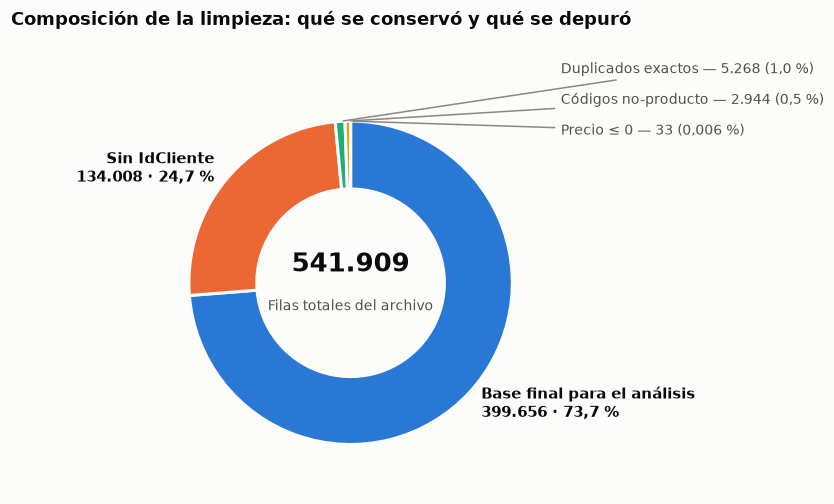

In [17]:
bit = pd.DataFrame(bitacora)
q = {r['Paso']: -r['Filas afectadas'] for _, r in bit.iloc[1:5].iterrows()}

total = len(df_raw)
etiquetas = ['Base final para el análisis', 'Sin IdCliente',
             'Duplicados exactos', 'Códigos no-producto', 'Precio ≤ 0']
valores = [len(base), q['3. Sin IdCliente'], q['1. Duplicados exactos'],
           q['2. Códigos no-producto'], q['4. PrecioUnitario <= 0']]
colores = [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA]

fig, ax = plt.subplots(figsize=(9.2, 5.4))
wedges, _ = ax.pie(valores, colors=colores, startangle=90, counterclock=False,
                   wedgeprops=dict(width=0.42, edgecolor=SUP, linewidth=2))

# Etiquetas directas junto a las dos porciones grandes
for w, etq, v in zip(wedges[:2], etiquetas[:2], valores[:2]):
    ang = np.deg2rad((w.theta1 + w.theta2) / 2)
    x, y = np.cos(ang), np.sin(ang)
    ax.text(1.1 * x, 1.1 * y,
            f'{etq}\n{miles(v)} · {miles(100 * v / total, 1)} %',
            ha='left' if x > 0 else 'right', va='center',
            color=TINTA, fontweight='bold', fontsize=10)

# Las tres porciones pequeñas, con línea guía y etiqueta apilada a la derecha
alturas = [1.32, 1.13, 0.94]
for w, etq, v, ytxt in zip(wedges[2:], etiquetas[2:], valores[2:], alturas):
    ang = np.deg2rad((w.theta1 + w.theta2) / 2)
    pct = 100 * v / total
    dec = 3 if pct < 0.1 else 1
    ax.annotate(f'{etq} — {miles(v)} ({miles(pct, dec)} %)',
                xy=(np.cos(ang), np.sin(ang)), xytext=(1.3, ytxt),
                ha='left', va='center', fontsize=9, color=TINTA2,
                arrowprops=dict(arrowstyle='-', color=TINTA3, lw=1))

# Total en el centro del anillo
ax.text(0, 0.07, miles(total), ha='center', fontsize=17, fontweight='bold', color=TINTA)
ax.text(0, -0.17, 'Filas totales del archivo', ha='center', fontsize=9, color=TINTA2)

ax.set_xlim(-2.1, 2.75)
ax.set_ylim(-1.3, 1.5)
ax.set_title('Composición de la limpieza: qué se conservó y qué se depuró')
fig.savefig(FIG / 'e1_composicion.png'); plt.show()

**Lectura de la gráfica:** de las **541.909** filas del dataset crudo se conserva el **73,7 %** (399.656) para el análisis por cliente. Una sola regla explica el **94 %** de lo depurado: los **134.008 registros sin `IdCliente`** (24,7 % del total). Las otras tres reglas juntas — duplicados (1,0 %), códigos no-producto (0,5 %) y precios inválidos (0,006 %) — suman apenas 8.245 filas (1,5 %). La base es de buena calidad salvo por un problema muy concreto y muy grande, que además **no se pierde**: el bloque sin identificador sigue disponible en el dataset A para el análisis por transacción.

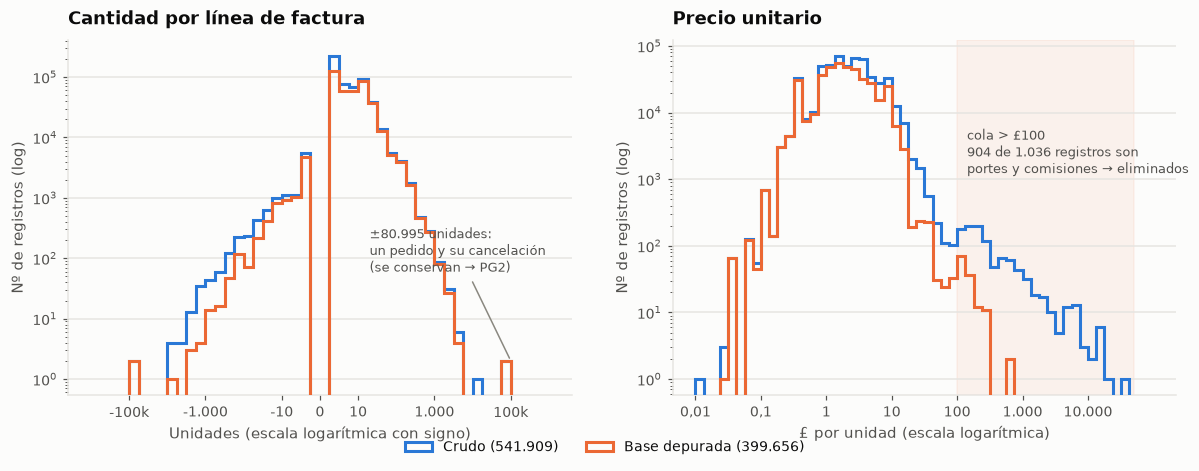

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# --- Cantidad: escala logarítmica con signo (hay valores negativos) --------
ax = axes[0]
bins = np.linspace(-6, 6, 49)
for datos, color, etq in [(df['Cantidad'], AZUL, f'Crudo ({miles(len(df_raw))})'),
                          (base['Cantidad'], NARANJA, f'Base depurada ({miles(len(base))})')]:
    v = np.sign(datos) * np.log10(np.abs(datos).clip(lower=1) + 1)
    ax.hist(v, bins=bins, histtype='step', lw=2, color=color, label=etq, zorder=3)
ax.set_yscale('log')
ax.set_xticks([-5, -3, -1, 0, 1, 3, 5], ['-100k', '-1.000', '-10', '0', '10', '1.000', '100k'])
ax.grid(axis='y', zorder=0)
ax.set_title('Cantidad por línea de factura')
ax.set_xlabel('Unidades (escala logarítmica con signo)')
ax.set_ylabel('Nº de registros (log)')
ax.annotate('±80.995 unidades:\nun pedido y su cancelación\n(se conservan → PG2)',
            xy=(5.0, 2), xytext=(1.3, 60), fontsize=8.5, color=TINTA2, ha='left',
            arrowprops=dict(arrowstyle='-', color=TINTA3, lw=1))

# --- Precio unitario: escala logarítmica ----------------------------------
ax = axes[1]
bins = np.linspace(-2, 5, 57)
for datos, color, etq in [(df['PrecioUnitario'], AZUL, 'Crudo'),
                          (base['PrecioUnitario'], NARANJA, 'Base depurada')]:
    ax.hist(np.log10(datos[datos > 0]), bins=bins, histtype='step',
            lw=2, color=color, zorder=3)
ax.set_yscale('log')
ax.set_xticks([-2, -1, 0, 1, 2, 3, 4], ['0,01', '0,1', '1', '10', '100', '1.000', '10.000'])
ax.grid(axis='y', zorder=0)
ax.set_title('Precio unitario')
ax.set_xlabel('£ por unidad (escala logarítmica)')
ax.set_ylabel('Nº de registros (log)')
ax.axvspan(2, 4.7, color=NARANJA, alpha=0.07, zorder=0)
ax.text(2.15, 6000, 'cola > £100\n904 de 1.036 registros son\nportes y comisiones → eliminados',
        fontsize=8.5, color=TINTA2, ha='left', va='top')

hs, ls = axes[0].get_legend_handles_labels()
fig.legend(hs, ls, loc='lower center', ncol=2, bbox_to_anchor=(0.5, -0.045))
fig.savefig(FIG / 'e1_distribuciones.png'); plt.show()

**Lectura de la gráfica:** las dos curvas se superponen en el **cuerpo central** de ambas distribuciones — la limpieza **no deformó los datos**, solo recortó los extremos que no eran ventas:

- **Cantidad:** desaparece buena parte de la cola negativa (devoluciones sin cliente identificado), pero **se conservan a propósito los ±80.995**: son el pedido más grande del año y su cancelación, exactamente el tipo de registro que **PG2** debe detectar.
- **Precio unitario:** la cola naranja se corta en seco a partir de **£100**. Ahí estaban los portes, las comisiones de Amazon y los ajustes contables — 904 de los 1.036 registros por encima de £100. El artículo más caro que queda en la base es real: una cesta de picnic de 60 piezas a **£649,50**.

Este es el argumento visual de por qué la limpieza era necesaria: sin ella, el algoritmo habría interpretado una comisión bancaria de £5.909 como "un cliente que compra productos carísimos".

## 1.9 Conclusiones del paso 1

| Problema | Magnitud | Decisión y justificación |
|---|---|---|
| **Cancelaciones** | 9.251 filas · **3.836 facturas (14,8 %)** · £471.751 | **Se conservan marcadas.** Un 5,4 % de devoluciones sobre lo facturado es un comportamiento de negocio relevante y será una *feature* del cliente |
| **`IdCliente` nulo** | 135.037 (25,2 %) | **Dos datasets.** Se excluyen del nivel cliente, se conservan en el de transacciones. Ningún análisis pierde información innecesariamente |
| **Duplicados exactos** | 5.268 (0,97 %) | Eliminados: registro repetido, no venta |
| **Códigos no-producto** | 2.944 (0,55 %) | Separados: son cargos administrativos |
| **`PrecioUnitario` ≤ 0** | 2.512 (0,47 %) | Excluidos del nivel cliente: no son venta real |
| **`Descripcion` nula** | 1.454 (0,27 %) | **Sin acción**: coinciden al 100 % con los dos casos anteriores |
| **Outliers extremos** | `Cantidad` ±80.995 · `PrecioUnitario` £38.970 | **No se eliminan aquí**: son precisamente lo que buscan PG2 y PG3. Se tratan en el paso 6 con Isolation Forest |

La base de trabajo conserva el **73,7 %** de los registros originales, **4.362 clientes** y **cero valores faltantes**.

---
# 2. Serie de tiempo

Con la base limpia, el siguiente paso es entender el **pulso temporal** del negocio: su ritmo semanal, su estacionalidad y si crece o no. No es un adorno: las *features* del paso 5 (`recencia`, `antiguedad_dias`, proporciones por franja) solo se interpretan bien conociendo el calendario sobre el que se calculan.

Se trabaja sobre el **dataset A** (transacciones) con una serie de **ventas brutas**: solo líneas de artículos (`EsProducto`), con precio válido y **sin** cancelaciones — la evolución temporal de las cancelaciones ya se estudió en 1.6. Las variables de calendario (`Fecha`, `Mes`, `DiaSemana`, `Hora`) quedaron creadas en 1.5.

## 2.1 De 522.537 líneas de factura a una serie diaria y mensual

`FechaHora` pasa a ser el **índice datetime**, lo que habilita `resample()`: agregación por día (`'D'`) para el ritmo de corto plazo y por mes (`'MS'`) para la estacionalidad. La agregación mensual incluye facturas y clientes únicos para poder distinguir después si un pico viene de *más pedidos* o de *pedidos más grandes*.

In [19]:
ventas = df_trans[df_trans['EsProducto'] & ~df_trans['EsCancelacion']
                  & (df_trans['PrecioUnitario'] > 0)]

serie   = ventas.set_index('FechaHora').sort_index()      # índice datetime
diario  = serie['ValorTotal'].resample('D').sum()         # £ vendidos por día
movil   = diario.rolling(7, center=True).mean()           # ventana semanal exacta
mensual = serie.resample('MS').agg(Ventas=('ValorTotal', 'sum'),
                                   Facturas=('Factura', 'nunique'),
                                   Clientes=('IdCliente', 'nunique'))
mensual['TicketFactura'] = mensual['Ventas'] / mensual['Facturas']

cerrados = diario[diario == 0]
print(f"Líneas de venta bruta : {miles(len(ventas))}  →  £{miles(ventas['ValorTotal'].sum())}")
print(f"Días de calendario    : {len(diario)}  ({diario.index[0]:%d-%m-%Y} → {diario.index[-1]:%d-%m-%Y})")
print(f"Días sin ventas       : {len(cerrados)} — los {(cerrados.index.dayofweek == 5).sum()} sábados del rango"
      f" ({(diario.index.dayofweek == 5).sum()}) más festivos y cierre navideño")
print(f"Día típico con ventas : mediana £{miles(diario[diario > 0].median())} · media £{miles(diario[diario > 0].mean())}")
mensual.round(0)

Líneas de venta bruta : 522.537  →  £10.247.219
Días de calendario    : 374  (01-12-2010 → 09-12-2011)
Días sin ventas       : 69 — los 53 sábados del rango (53) más festivos y cierre navideño
Día típico con ventas : mediana £28.509 · media £33.597


,Ventas,Facturas,Clientes,TicketFactura
FechaHora,,,,
2010-12-01,"775,638.00",1550,884,500.00
2011-01-01,"670,380.00",1081,739,620.00
2011-02-01,"507,800.00",1093,757,465.00
2011-03-01,"689,834.00",1440,973,479.00
2011-04-01,"515,378.00",1235,853,417.00
2011-05-01,"739,953.00",1668,1054,444.00
2011-06-01,"737,559.00",1525,990,484.00
2011-07-01,"688,219.00",1452,946,474.00
2011-08-01,"724,216.00",1339,933,541.00


**Lectura del remuestreo:** el calendario comercial de la tienda queda al descubierto con solo contar los días en cero:

- **Los 53 sábados del rango están en cero: la tienda no opera los sábados.** El resto de días sin ventas son el **cierre navideño** (24-dic → 3-ene) y los festivos del Reino Unido de 2011: Viernes Santo (22-abr), Lunes de Pascua (25-abr), la boda real (29-abr) y los *bank holidays* de mayo (2 y 30) y agosto (29).
- El **domingo** se vende menos de la mitad que un día laborable (media £16k frente a £34–40k).
- La **media diaria (£33,6k) supera a la mediana (£28,5k)**: la distribución tiene cola derecha — hay días inflados por pedidos puntuales enormes, que se identifican en la gráfica siguiente.

Implicación para el paso 5: la *feature* `prop_sab_dom` medirá en la práctica **compra dominical**, un rasgo minoritario que puede distinguir al comprador ocasional del mayorista de lunes a viernes.

## 2.2 Serie diaria: el ritmo del negocio en una sola gráfica

Serie diaria más **media móvil centrada de 7 días**: la ventana semanal exacta neutraliza el ciclo sábado/domingo y deja ver el nivel real de actividad.

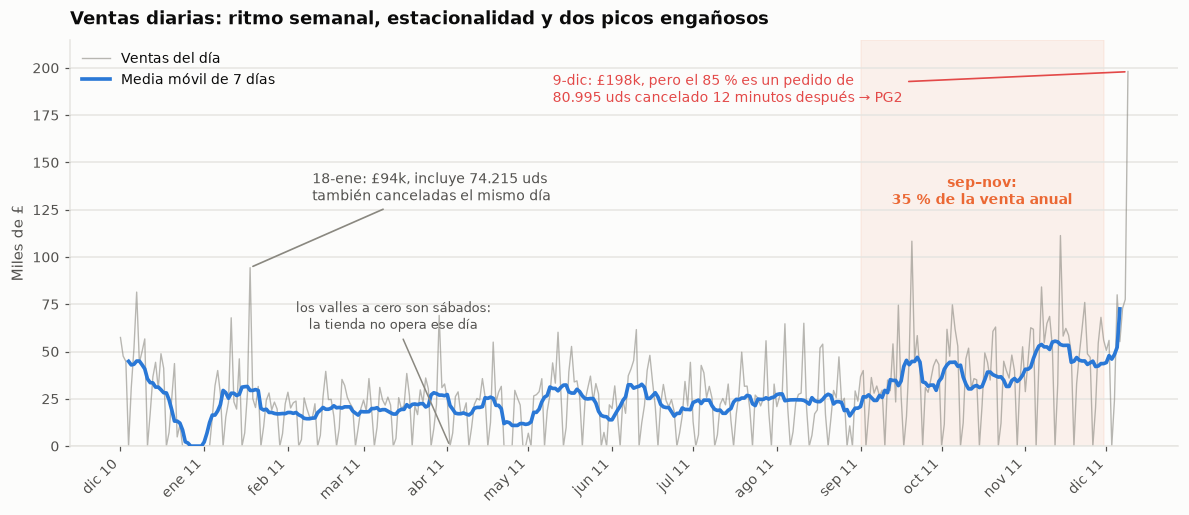

In [20]:
MES_ABR = ['ene', 'feb', 'mar', 'abr', 'may', 'jun',
           'jul', 'ago', 'sep', 'oct', 'nov', 'dic']

fig, ax = plt.subplots(figsize=(13, 4.8))

ax.plot(diario.index, diario / 1000, color=TINTA3, lw=0.9, alpha=0.6,
        label='Ventas del día', zorder=2)
ax.plot(movil.index, movil / 1000, color=AZUL, lw=2.4,
        label='Media móvil de 7 días', zorder=3)

# Campaña de fin de año
ax.axvspan(pd.Timestamp('2011-09-01'), pd.Timestamp('2011-11-30'),
           color=NARANJA, alpha=0.08, zorder=0)
ax.text(pd.Timestamp('2011-10-16'), 128, 'sep–nov:\n35 % de la venta anual',
        ha='center', fontsize=9, color=NARANJA, fontweight='bold')

# Los dos picos del año no son días extraordinarios: son pedidos cancelados
ax.annotate('9-dic: £198k, pero el 85 % es un pedido de\n80.995 uds cancelado 12 minutos después → PG2',
            xy=(pd.Timestamp('2011-12-09'), 198), xytext=(pd.Timestamp('2011-05-10'), 182),
            fontsize=9, color=ROJO, ha='left',
            arrowprops=dict(arrowstyle='-', color=ROJO, lw=1.1))
ax.annotate('18-ene: £94k, incluye 74.215 uds\ntambién canceladas el mismo día',
            xy=(pd.Timestamp('2011-01-18'), 94.4), xytext=(pd.Timestamp('2011-02-10'), 130),
            fontsize=9, color=TINTA2, ha='left',
            arrowprops=dict(arrowstyle='-', color=TINTA3, lw=1.1))

# El ritmo de sierra semanal
ax.annotate('los valles a cero son sábados:\nla tienda no opera ese día',
            xy=(pd.Timestamp('2011-04-02'), 0), xytext=(pd.Timestamp('2011-03-12'), 62),
            fontsize=8.5, color=TINTA2, ha='center',
            arrowprops=dict(arrowstyle='-', color=TINTA3, lw=1))

meses = pd.date_range('2010-12-01', '2011-12-01', freq='MS')
ax.set_xticks(meses, [f'{MES_ABR[m.month - 1]} {str(m.year)[2:]}' for m in meses],
              rotation=45, ha='right')
ax.set_ylim(0, 215)
ax.grid(axis='y', zorder=0)
ax.set_title('Ventas diarias: ritmo semanal, estacionalidad y dos picos engañosos')
ax.set_ylabel('Miles de £')
ax.legend(loc='upper left')
fig.savefig(FIG / 'e2_serie_diaria.png'); plt.show()

**Lectura de la gráfica:** hay tres estructuras superpuestas:

1. **Ritmo de sierra semanal.** Las caídas a cero son los sábados; los domingos operan a medio ritmo. La media móvil de 7 días (azul) elimina ese ciclo y muestra el nivel real.
2. **Estacionalidad de fin de año.** El negocio se mueve estable en torno a £30k/día de diciembre a agosto y despega desde septiembre: la media móvil sube de ~£30k a un máximo de **£72,6k el 6-dic**, más que duplicando el nivel del resto del año.
3. **Los dos picos más altos del año son ficticios.** El 9-dic marca £198k, pero el 85 % es **un solo pedido de 80.995 unidades cancelado 12 minutos después** (cliente 16446, cuyo historial previo eran dos cepillos de cocina por £2,90). El 18-ene marca £94k, con **74.215 unidades canceladas el mismo día** (cliente 12346, sin ninguna otra compra en el año). Ninguno de los dos representa venta real.

El punto 3 es el argumento visual de **PG2 y PG3**: existen transacciones y clientes que distorsionan cualquier agregado, y un análisis que no los aísle los confundiría con "clientes estrella".

## 2.3 El calendario completo: la prueba del sábado

Una afirmación fuerte merece su propia gráfica: ¿de verdad **ningún** sábado del año registró ventas? En la serie diaria los ceros se pierden entre las oscilaciones; la forma contundente de demostrarlo es un **calendario día × semana**: si la tienda no opera los sábados, la fila completa del sábado debe quedar en blanco de la primera a la última semana.

Sábados dentro del rango de datos : 53
Venta acumulada en TODOS ellos    : £0
Sábados con al menos una venta    : 0


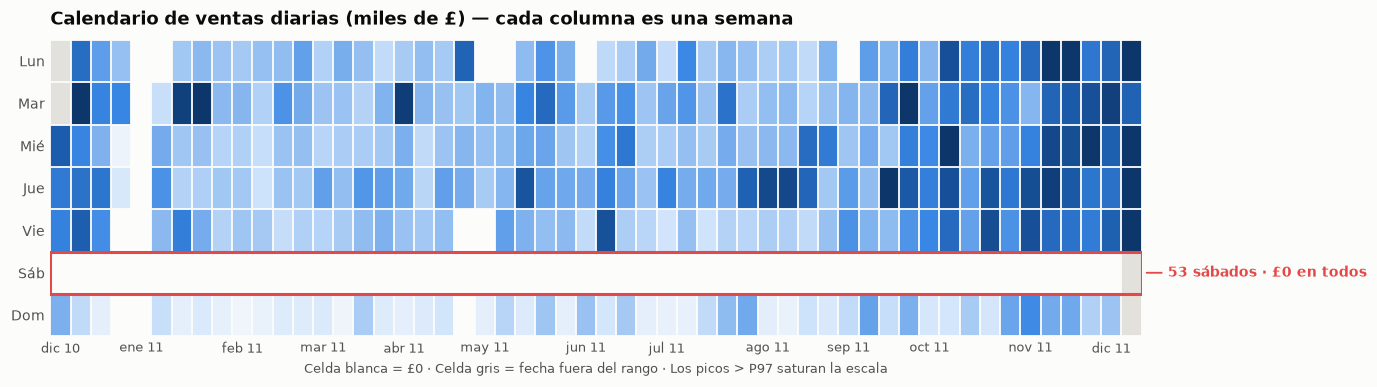

In [21]:
# Calendario: filas = día de la semana, columnas = las 54 semanas del rango
diario_cal = ventas.set_index('FechaHora')['ValorTotal'].resample('D').sum()
origen = diario_cal.index.min() - pd.Timedelta(days=int(diario_cal.index.min().dayofweek))
cal = pd.DataFrame({'Miles': diario_cal.values / 1000,
                    'Dia': diario_cal.index.dayofweek,
                    'Semana': (diario_cal.index - origen).days // 7})
M = cal.pivot_table(index='Dia', columns='Semana', values='Miles').reindex(range(7))

sabados = diario_cal[diario_cal.index.dayofweek == 5]
print(f'Sábados dentro del rango de datos : {len(sabados)}')
print(f'Venta acumulada en TODOS ellos    : £{sabados.sum():,.0f}')
print(f'Sábados con al menos una venta    : {(sabados > 0).sum()}')

CM_CAL = mpl.colors.LinearSegmentedColormap.from_list(
    'cal', [SUP, '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b']).copy()
CM_CAL.set_bad('#e3e1dc')                     # gris: fecha fuera del rango de datos

fig, ax = plt.subplots(figsize=(12.8, 3.5))
ax.imshow(np.ma.masked_invalid(M.values), cmap=CM_CAL, aspect='auto',
          vmin=0, vmax=np.nanpercentile(M.values, 97))
ax.set_yticks(range(7), ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom'], fontsize=9)
inicios = pd.date_range('2010-12-01', '2011-12-01', freq='MS')
ax.set_xticks([(d - origen).days // 7 for d in inicios],
              [f'{MES_ABR[d.month - 1]} {str(d.year)[2:]}' for d in inicios], fontsize=8.5)
ax.set_xticks(np.arange(-0.5, M.shape[1]), minor=True)
ax.set_yticks(np.arange(-0.5, 7), minor=True)
ax.grid(which='minor', color=SUP, linewidth=1.2)
ax.tick_params(which='both', length=0)
for lado in ax.spines.values():
    lado.set_visible(False)

# La fila del sábado, resaltada: blanca de punta a punta
ax.add_patch(mpl.patches.Rectangle((-0.5, 4.5), M.shape[1], 1, fill=False,
                                   edgecolor=ROJO, lw=2, zorder=4))
ax.annotate(f'{len(sabados)} sábados · £0 en todos', xy=(M.shape[1] - 0.4, 5),
            xytext=(M.shape[1] + 0.8, 5), fontsize=9, color=ROJO, fontweight='bold',
            va='center', annotation_clip=False,
            arrowprops=dict(arrowstyle='-', color=ROJO, lw=1.2))
ax.set_title('Calendario de ventas diarias (miles de £) — cada columna es una semana')
ax.set_xlabel('Celda blanca = £0 · Celda gris = fecha fuera del rango · Los picos > P97 saturan la escala',
              fontsize=8.5)
fig.savefig(FIG / 'e2_calendario.png'); plt.show()

**Lectura de la gráfica:** la fila del sábado (recuadro rojo) es una franja **blanca de la primera a la última semana**: los 53 sábados del rango suman exactamente £0 — no es un día flojo, es un día en el que la operación **no existe** (la plataforma no registra pedidos). El calendario regala además tres confirmaciones de un vistazo: el **cierre navideño** (celdas blancas entre el 24-dic-2010 y el 3-ene-2011, arranque del rango), los **festivos británicos** sueltos (celdas blancas aisladas en lunes y viernes), y la **escalada de fin de año** (las columnas de sep–nov se oscurecen en todos los días hábiles a la vez). Consecuencia directa para la matriz de clientes del paso 5: no existe `prop_sab`, y el "fin de semana" real del negocio es solo el domingo.

## 2.4 Serie mensual: la estacionalidad de fin de año

La vista mensual responde dos preguntas: **¿cuánto pesa la campaña navideña?** y **¿el pico viene de más clientes o de pedidos más grandes?**

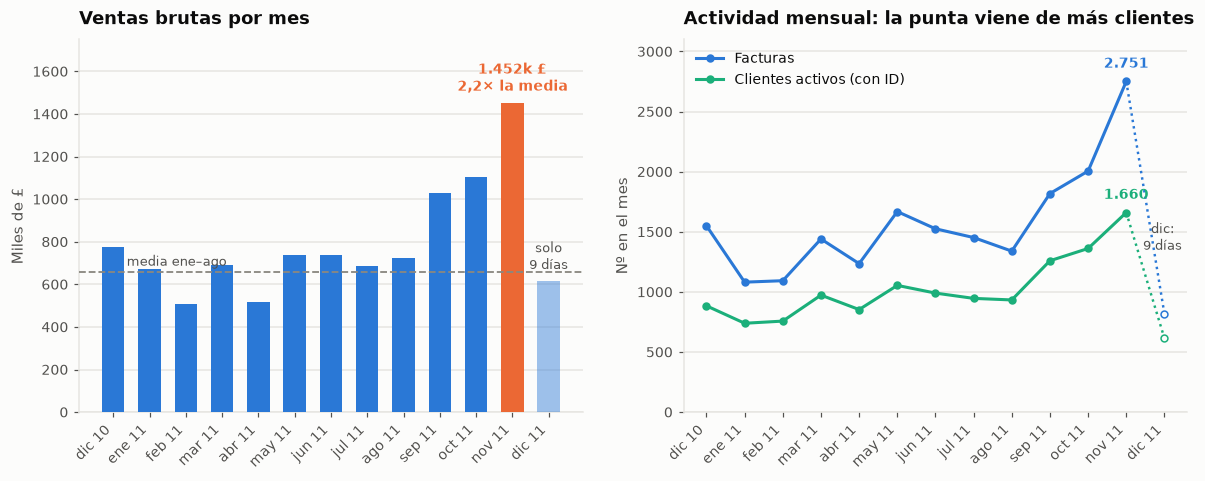

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
x = np.arange(len(mensual))
etiq = [f'{MES_ABR[d.month - 1]} {str(d.year)[2:]}' for d in mensual.index]

# --- Ventas por mes --------------------------------------------------------
ax = axes[0]
colores = [NARANJA if (d.year, d.month) == (2011, 11) else AZUL for d in mensual.index]
barras = ax.bar(x, mensual['Ventas'] / 1000, color=colores, width=0.62, zorder=3)
barras[-1].set_alpha(0.45)                            # dic-2011: mes incompleto
media = mensual['Ventas'].iloc[1:9].mean() / 1000     # media ene–ago 2011
ax.axhline(media, color=TINTA3, ls='--', lw=1.2, zorder=4)
ax.text(1.75, media + 28, 'media ene–ago', ha='center', fontsize=8.5, color=TINTA2)
ax.annotate(f"{miles(mensual['Ventas'].iloc[11] / 1000)}k £\n2,2× la media",
            xy=(11, mensual['Ventas'].iloc[11] / 1000), xytext=(0, 8),
            textcoords='offset points', ha='center',
            fontsize=9, color=NARANJA, fontweight='bold')
ax.annotate('solo\n9 días', xy=(12, mensual['Ventas'].iloc[12] / 1000),
            xytext=(0, 8), textcoords='offset points', ha='center',
            fontsize=8.5, color=TINTA2)
ax.set_xticks(x, etiq, rotation=45, ha='right')
ax.set_ylim(0, 1750)
ax.grid(axis='y', zorder=0)
ax.set_title('Ventas brutas por mes')
ax.set_ylabel('Miles de £')

# --- Facturas y clientes por mes -------------------------------------------
ax = axes[1]
for col, color, etq2 in [('Facturas', AZUL, 'Facturas'),
                         ('Clientes', AQUA, 'Clientes activos (con ID)')]:
    ax.plot(x[:12], mensual[col].iloc[:12], color=color, marker='o', ms=4.5,
            zorder=3, label=etq2)
    ax.plot(x[11:], mensual[col].iloc[11:], color=color, ls=':', lw=1.6, zorder=3)
    ax.plot(x[12], mensual[col].iloc[12], marker='o', ms=4.5, color=color,
            markerfacecolor=SUP, zorder=3)
    ax.annotate(miles(mensual[col].iloc[11]), (11, mensual[col].iloc[11]),
                textcoords='offset points', xytext=(0, 9), ha='center',
                fontsize=9, color=color, fontweight='bold')
ax.text(11.95, 1350, 'dic:\n9 días', ha='center', fontsize=8.5, color=TINTA2)
ax.set_xticks(x, etiq, rotation=45, ha='right')
ax.set_ylim(0, 3100)
ax.grid(axis='y', zorder=0)
ax.set_title('Actividad mensual: la punta viene de más clientes')
ax.set_ylabel('Nº en el mes')
ax.legend(loc='upper left')
fig.savefig(FIG / 'e2_serie_mensual.png'); plt.show()

**Lectura de la gráfica:**

- **Izquierda — el peso de la campaña.** Septiembre, octubre y noviembre suben en escalera hasta **£1,45M en noviembre, 2,2× la media de enero–agosto (£659k)**; entre los tres concentran el **35 % de la venta anual**. Que el pico sea **noviembre y no diciembre** delata el perfil mayorista: quien revende se abastece con antelación a la Navidad.
- **Derecha — de dónde sale el pico.** La punta no la explican pedidos más caros sino **más actividad**: 2.751 facturas y 1.660 clientes activos en noviembre, frente a ~1.350 y ~900 de media entre enero y agosto. El ticket por factura apenas se mueve (£417–£620 todo el año).
- **Cuidado con diciembre-2011:** la barra "cae" porque solo registra 9 días. La comparación honesta contra los **mismos 9 días de 2010** da £614k vs £408k = **+51 % aparente**… pero £168k son el pedido fantasma del 9-dic. Sin él quedan £446k: **+9,3 % real**, con +7 % de clientes (614 vs 572) y facturas estables (816 vs 830).

Ese último punto es la mejor motivación de **PG2**: una sola transacción anómala convierte un crecimiento real del 9 % en uno aparente del 51 %.

## 2.5 Conclusiones del paso 2

| Hallazgo | Evidencia | Implicación para los pasos siguientes |
|---|---|---|
| **Estacionalidad de fin de año** | sep–nov = 35 % de la venta anual; nov = 2,2× la media ene–ago | El pico en **noviembre** (no diciembre) confirma la base mayorista. La `recencia` del paso 5 se mide al 2011-12-10, en plena campaña: los segmentos deben leerse con el calendario en mente |
| **Calendario comercial** | 53/53 sábados en cero; cierre 24-dic → 3-ene; festivos UK | La tienda no opera los sábados → `prop_sab_dom` capturará compra **dominical** (paso 5) y las franjas del paso 3 se leen sobre 6 días |
| **El pico viene de más clientes** | 1.660 clientes activos y 2.751 facturas en nov; ticket estable £417–620 | La estacionalidad es de *volumen de clientes*: rasgo colectivo, no de un segmento de tickets grandes |
| **Los picos diarios son ficticios** | 9-dic: 85 % de £198k cancelado a los 12 min · 18-ene: 74.215 uds canceladas el mismo día | Transacciones y clientes anómalos existen y distorsionan agregados → objetivo directo de **PG2/PG3** en el paso 6 |
| **Crecimiento real moderado** | Mismos 9 días de dic: +51 % aparente → **+9,3 %** sin el pedido fantasma | Reportar métricas sin depurar anomalías produce conclusiones falsas |
| **Dic-2011 incompleto** | Solo 9 días registrados | No compararlo como mes completo; fecha de referencia para `recencia`: **2011-12-10** |

---
# 3. Transformación y reestructuración

El dataset está en **formato largo**: una fila = una línea de factura. Casi ninguna pregunta de negocio se responde en ese formato; hay que **reestructurarlo** en tablas *entidad × dimensión* (`pivot_table`, `crosstab`) y **normalizarlas por fila** (`div(sum(axis=1), axis=0)`) para que entidades de tamaños muy distintos sean comparables entre sí.

Este paso es el ensayo general del paso 5: la matriz final de clientes se construye exactamente con estas técnicas. Se sigue trabajando sobre la serie de **ventas brutas** del paso 2 (`ventas`): solo artículos, precio válido, sin cancelaciones.

## 3.1 País × mes: perfiles estacionales comparables

¿Todos los mercados compran al mismo ritmo? En £ absolutas es imposible verlo: UK vende £8,7M y Suiza £53k, y cualquier gráfica conjunta aplasta a los pequeños. La solución es el patrón **pivot + normalización por fila**: cada país queda expresado como *su propio* perfil mensual (fila que suma 100 %), y todas las filas se leen en la misma escala.

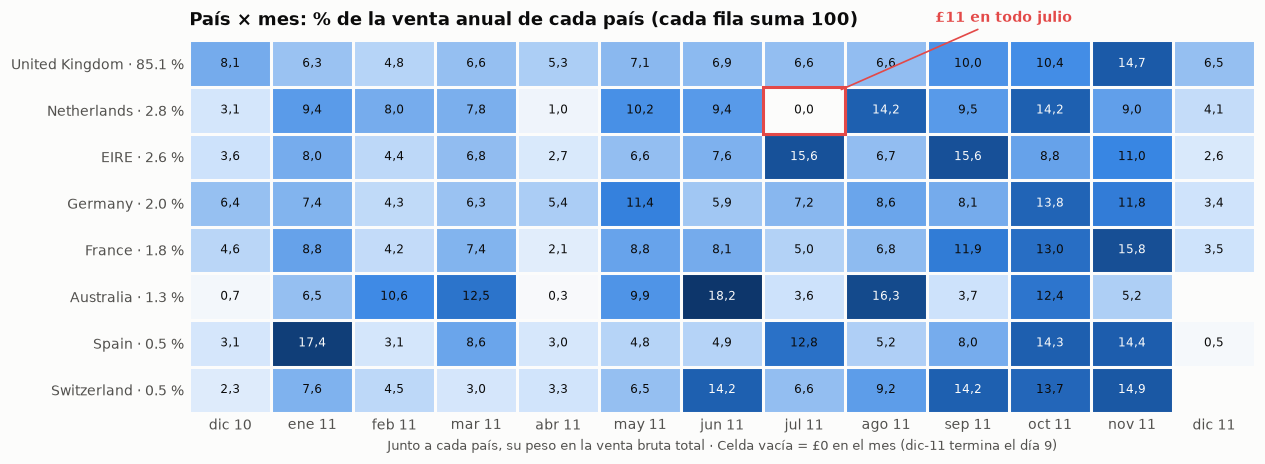

In [23]:
CM_AZUL = mpl.colors.LinearSegmentedColormap.from_list(
    'azul_sec', [SUP, '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])

def mapa_calor(tabla, ax, vmax=None, dec=1, tam=8):
    """Heatmap con etiquetas directas; celda vacía = cero exacto (ver pie)."""
    vmax = vmax if vmax is not None else float(tabla.values.max())
    ax.imshow(tabla.values, cmap=CM_AZUL, vmin=0, vmax=vmax, aspect='auto')
    ax.set_xticks(range(tabla.shape[1]), tabla.columns, fontsize=9)
    ax.set_yticks(range(tabla.shape[0]), tabla.index, fontsize=9)
    ax.set_xticks(np.arange(-0.5, tabla.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, tabla.shape[0]), minor=True)
    ax.grid(which='minor', color=SUP, linewidth=2)
    ax.tick_params(which='both', length=0)
    for lado in ax.spines.values():
        lado.set_visible(False)
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            v = tabla.values[i, j]
            if v == 0:
                continue
            ax.text(j, i, f'{v:.{dec}f}'.replace('.', ','), ha='center',
                    va='center', fontsize=tam,
                    color=SUP if v > 0.75 * vmax else TINTA)

tot = ventas['ValorTotal'].sum()
top8 = ventas.groupby('Pais')['ValorTotal'].sum().nlargest(8)
pais_mes = (ventas[ventas['Pais'].isin(top8.index)]
            .pivot_table(index='Pais', columns='Mes', values='ValorTotal',
                         aggfunc='sum', fill_value=0)
            .reindex(top8.index))
pais_mes_pct = 100 * pais_mes.div(pais_mes.sum(axis=1), axis=0)   # cada fila suma 100

fig, ax = plt.subplots(figsize=(12.5, 4.4))
tabla = pais_mes_pct.copy()
tabla.index = [f'{p} · {100 * v / tot:.1f} %' for p, v in top8.items()]
tabla.columns = [f'{MES_ABR[int(m[5:]) - 1]} {m[2:4]}' for m in tabla.columns]
mapa_calor(tabla, ax)

# La celda más rara del año: el país nº 2 vendió £11 en todo julio
i = list(pais_mes_pct.index).index('Netherlands')
j = list(pais_mes_pct.columns).index('2011-07')
ax.add_patch(mpl.patches.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False,
                                   edgecolor=ROJO, lw=2, zorder=4))
ax.annotate('£11 en todo julio', xy=(j + 0.42, i - 0.42), xytext=(j + 1.6, -0.9),
            fontsize=9, color=ROJO, fontweight='bold', ha='left',
            annotation_clip=False,
            arrowprops=dict(arrowstyle='-', color=ROJO, lw=1.1))
ax.set_title('País × mes: % de la venta anual de cada país (cada fila suma 100)')
ax.set_xlabel('Junto a cada país, su peso en la venta bruta total · '
              'Celda vacía = £0 en el mes (dic-11 termina el día 9)', fontsize=8.5)
fig.savefig(FIG / 'e3_pais_mes.png'); plt.show()

**Lectura de la gráfica:** el % junto a cada país es su peso en la venta bruta total; las celdas, su calendario propio.

- **UK pesa el 85,1 % de las £** (aunque era el 91,4 % de los registros crudos: la línea extranjera media es más mayorista). Su perfil es el "oficial": mínimo en febrero (4,8 %), meseta de mayo a agosto y escalada sep → oct → nov (10,0 → 10,4 → 14,7 %).
- **La estacionalidad navideña no es universal.** Francia es el país grande más navideño (nov = 15,8 %; sep–nov = 40,7 %) y Suiza le sigue (42,8 % en sep–nov, frente al 35,2 % de UK). **Australia va a contracorriente**: su pico es junio (18,2 %) y sep–nov apenas suma 21,4 %, con £0 en el dic parcial.
- **La celda roja:** Holanda —segundo país en ventas— facturó **£11,02 en todo julio** (una única factura de 9 unidades). Un "país" no puede apagarse un mes… salvo que no sea un país: el 98,3 % de la venta holandesa es **un solo cliente** (14646, que además es el nº 1 global de la tienda con £279k, por encima del mejor de UK). Lo mismo Australia (90,2 % = cliente 12415) y EIRE (3 clientes = 94,9 %).

**Moraleja para PG1/PG3:** fuera de UK (3.916 clientes, ninguno pesa más del 3 %), varios "países" son la sombra de un único mayorista. La geografía **no** sirve como segmento: la unidad de análisis correcta es el **cliente** — la regla de oro de la actividad.

## 3.2 Hora × día de semana: el horario práctico de la tienda

Ahora la entidad es el **día de la semana** y la dimensión, la **hora**. Se trabaja a nivel de **factura única** (no de línea) para no inflar las horas de los pedidos con muchos artículos: cada factura toma su primera marca de tiempo (42 tienen más de una) y de paso queda construida `fact`, la tabla de facturas que reutilizará el paso 6. La `crosstab` se normaliza por fila de día: *del total de facturas del jueves, ¿qué % cae a cada hora?*

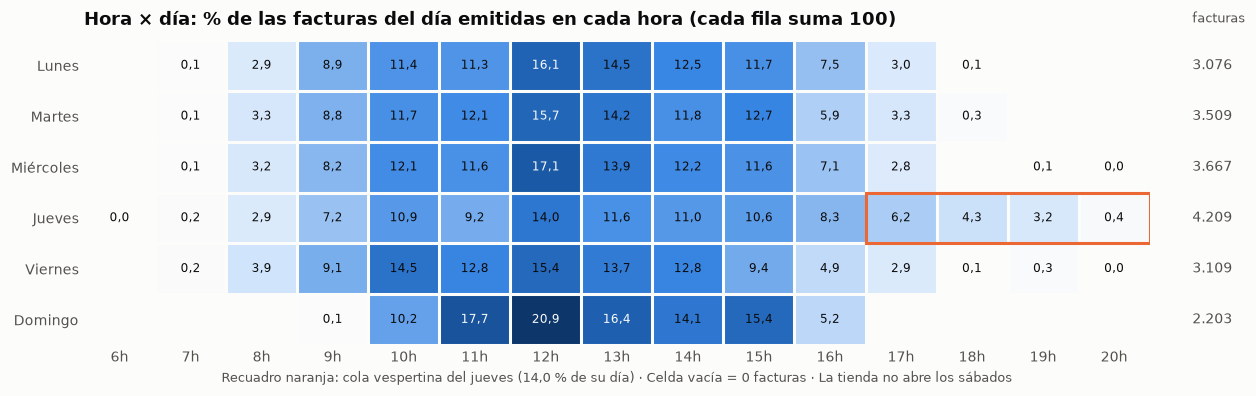

In [24]:
ETIQ_DIA = {0: 'Lunes', 1: 'Martes', 2: 'Miércoles', 3: 'Jueves', 4: 'Viernes', 6: 'Domingo'}

# Tabla a nivel FACTURA (insumo del paso 6): primera marca de tiempo de cada una
fact = (ventas.sort_values('FechaHora')
              .groupby('Factura')
              .agg(FechaHora=('FechaHora', 'first'),
                   IdCliente=('IdCliente', 'first'),
                   Importe=('ValorTotal', 'sum'),
                   Lineas=('ValorTotal', 'size')))
fact['Dia'] = fact['FechaHora'].dt.dayofweek.map(ETIQ_DIA)
fact['Hora'] = fact['FechaHora'].dt.hour

dia_hora = pd.crosstab(fact['Dia'], fact['Hora']).reindex(list(ETIQ_DIA.values()))
dia_hora_pct = 100 * dia_hora.div(dia_hora.sum(axis=1), axis=0)   # cada día suma 100

fig, ax = plt.subplots(figsize=(12.5, 3.6))
mapa_calor(dia_hora_pct, ax)
ax.set_xticks(range(dia_hora_pct.shape[1]),
              [f'{h}h' for h in dia_hora_pct.columns], fontsize=9)

# Total de facturas de cada día, al margen derecho
for i, n in enumerate(dia_hora.sum(axis=1)):
    ax.text(dia_hora_pct.shape[1] + 0.1, i, miles(n), va='center',
            fontsize=9, color=TINTA2, clip_on=False)
ax.text(dia_hora_pct.shape[1] + 0.1, -0.85, 'facturas', fontsize=8.5,
        color=TINTA2, clip_on=False)

# La única cola vespertina real del comercio: el jueves
i = list(dia_hora_pct.index).index('Jueves')
j = list(dia_hora_pct.columns).index(17)
ax.add_patch(mpl.patches.Rectangle((j - 0.5, i - 0.5), 4, 1, fill=False,
                                   edgecolor=NARANJA, lw=2, zorder=4))
ax.set_title('Hora × día: % de las facturas del día emitidas en cada hora (cada fila suma 100)')
ax.set_xlabel('Recuadro naranja: cola vespertina del jueves (14,0 % de su día) · '
              'Celda vacía = 0 facturas · La tienda no abre los sábados', fontsize=8.5)
fig.savefig(FIG / 'e3_hora_dia.png'); plt.show()

**Lectura de la gráfica:** es un negocio de **6 horas centrales**: el 77,8 % de las 19.773 facturas se emite entre las 10:00 y las 15:59, con la celda pico en **miércoles a las 12 h** (626 facturas). Sobre esa base común, cada día tiene su matiz:

- **Jueves es el día fuerte** (4.209 facturas) y el único con cola vespertina real (recuadro naranja): de 17 a 20 h emite el 14,0 % de su día, cuando lunes, martes, miércoles y viernes prácticamente mueren a las 18 h.
- **El domingo opera comprimido**: abre a las 10 (solo 2 facturas a las 9 h), cierra a las 16 y su mediodía concentra el 20,9 % del día. Es además el día más débil (2.203 facturas).
- **La hora cambia el tipo de pedido** (dato a nivel de línea, fuera del heatmap): las facturas de las 9 h promedian **£650** frente a **£441** a las 12 h; como la *mediana* baja suavemente a lo largo del día (£324 → £231), esa ventaja matinal la crean **pocos pedidos mayoristas grandes**, no el cliente típico.
- **Bonus sobre el dataset completo (con cancelaciones):** la tasa de cancelación por factura escala con la hora: 13,5 % global → 19,7 % (16 h) → 23,7 % (17 h) → 32,2 % (19 h) → 33,3 % (20 h). Las devoluciones se procesan al cierre del día — y la única actividad a las 6 h de todo el año ocurre el 18-ago: **19 facturas de cancelación de 19 clientes distintos en 29 minutos** (06:10–06:39), contra una sola venta de £4,25 — back-office puro. Ambas cosas alimentan el contexto de **PG2** en el paso 6.

## 3.3 Franjas horarias con `pd.cut` y categoría dominante con `idxmax`

La hora exacta es demasiado granular para describir a un cliente; `pd.cut` la discretiza en **franjas con nombre de negocio**. Después, la receta `crosstab(cliente × franja) → idxmax(axis=1)` responde: *¿en qué franja compra más cada cliente?* — el prototipo exacto de las *features* de proporción del paso 5.

In [25]:
FRANJAS = [6, 10, 13, 17, 21]
ETIQ_FRANJA = ['Mañana (6–10)', 'Media mañana (10–13)', 'Tarde (13–17)', 'Cierre (17–21)']
fact['Franja'] = pd.cut(fact['Hora'], bins=FRANJAS, labels=ETIQ_FRANJA, right=False)

resumen_franja = pd.DataFrame({
    'Facturas': fact['Franja'].value_counts().sort_index(),
    '% facturas': (100 * fact['Franja'].value_counts(normalize=True).sort_index()).round(1),
    '% de £': (100 * fact.groupby('Franja', observed=False)['Importe'].sum()
               / fact['Importe'].sum()).round(1),
    'Ticket mediano £': fact.groupby('Franja', observed=False)['Importe'].median().round(1),
})
display(resumen_franja)

# --- Franja dominante por cliente: crosstab + idxmax -----------------------
con_id = fact[fact['IdCliente'].notna()].copy()
cli_franja = pd.crosstab(con_id['IdCliente'], con_id['Franja'])
dominante = cli_franja.idxmax(axis=1)                    # franja con más facturas
concentracion = cli_franja.max(axis=1) / cli_franja.sum(axis=1)
gasto = con_id.groupby('IdCliente')['Importe'].sum()

perfil_franja = pd.DataFrame({
    'Clientes': dominante.value_counts().sort_index(),
    '% clientes': (100 * dominante.value_counts(normalize=True).sort_index()).round(1),
    'Gasto bruto mediano £': gasto.groupby(dominante, observed=False).median().round(0),
})

multi = cli_franja.sum(axis=1) >= 2
print(f'Clientes identificados con al menos una compra   : {miles(len(cli_franja))}')
print(f'≥50 % de sus facturas en su franja dominante      : {100 * (concentracion >= 0.5).mean():.1f} %'
      f'  (≥80 %: {100 * (concentracion >= 0.8).mean():.1f} %)')
print(f'… pero el {100 * (~multi).mean():.1f} % tiene una sola factura. Solo multicompra (≥2):'
      f' ≥50 % → {100 * (concentracion[multi] >= 0.5).mean():.1f} %,'
      f' ≥80 % → {100 * (concentracion[multi] >= 0.8).mean():.1f} %')

# --- Día dominante por cliente: misma receta --------------------------------
# Reindex cronológico: crosstab ordena alfabéticamente y, en caso de empate,
# idxmax devuelve la PRIMERA columna — el orden de desempate debe ser explícito
dia_dom = (pd.crosstab(con_id['IdCliente'], con_id['Dia'])
             .reindex(columns=list(ETIQ_DIA.values()))
             .idxmax(axis=1))
print('\nDía dominante (% de clientes):')
print((100 * dia_dom.value_counts(normalize=True))
      .reindex(list(ETIQ_DIA.values())).round(1).to_string())
perfil_franja

,Facturas,% facturas,% de £,Ticket mediano £
Franja,,,,
Mañana (6–10),2066,10.40,12.30,318.30
Media mañana (10–13),7916,40.00,39.10,306.00
Tarde (13–17),8774,44.40,42.20,293.10
Cierre (17–21),1017,5.10,6.30,234.00


Clientes identificados con al menos una compra   : 4.334
≥50 % de sus facturas en su franja dominante      : 92.1 %  (≥80 %: 51.6 %)
… pero el 34.7 % tiene una sola factura. Solo multicompra (≥2): ≥50 % → 87.9 %, ≥80 % → 25.9 %



Día dominante (% de clientes):
Lunes       21.70
Martes      19.90
Miércoles   18.20
Jueves      19.90
Viernes     10.70
Domingo      9.60


,Clientes,% clientes,Gasto bruto mediano £
Mañana (6–10),515,11.90,616.00
Media mañana (10–13),1929,44.50,759.00
Tarde (13–17),1777,41.00,620.00
Cierre (17–21),113,2.60,318.00


**Lectura de las tablas:**

- **El reparto del día:** media mañana y tarde concentran el 84,4 % de las facturas. La mañana pesa más en £ (12,3 %) que en facturas (10,4 %) — pedidos más grandes — y el ticket mediano cae a lo largo del día (ver tabla). Ojo metodológico: el corte de las 13 h parte el pico natural 12–13 h (30,0 % de las facturas juntas); las franjas son una discretización de lectura, no una *feature* definitiva.
- **La franja dominante discrimina poco:** el 85,5 % de los clientes cae en solo dos categorías (media mañana 44,5 % + tarde 41,0 %). Los perfiles minoritarios sí dicen algo: los 113 clientes "de cierre" (2,6 %) son los más chicos en todo (gasto mediano £318 frente a £759 de media mañana).
- **¿Hábito o artefacto?** El 92,1 % de los clientes tiene ≥50 % de sus facturas en su franja dominante… pero el 34,7 % compró una sola vez (concentración trivial). Entre los 2.829 clientes multicompra la cifra honesta es 87,9 % (≥50 %) y **25,9 % (≥80 %)**: 1 de cada 4 clientes recurrentes compra casi siempre a la misma hora.
- **El día dominante reparte mucho mejor** (lunes 21,7 %, martes/jueves 19,9 %, miércoles 18,2 %, viernes 10,7 %, domingo 9,6 %): hay variación real entre clientes. **Decisión de diseño para el paso 5:** las proporciones por cliente se calcularán por **día de semana** (lun–mié / jue–vie / dom), no por franja horaria.

## 3.4 Cliente × mes: la recurrencia ya insinúa los segmentos

Una última reestructuración, esta vez con el **cliente** como entidad: `crosstab(cliente × mes)` cuenta en cuántos meses distintos compró cada uno. Es la antesala directa de la *feature* `frecuencia` del paso 5 — y ya separa a la clientela en capas de valor muy distintas.

In [26]:
con_id['Mes'] = con_id['FechaHora'].dt.to_period('M').astype(str)
cli_mes = pd.crosstab(con_id['IdCliente'], con_id['Mes'])          # cliente × mes
meses_activos = cli_mes.gt(0).sum(axis=1)
tipo = pd.cut(meses_activos, bins=[0, 1, 5, 13],
              labels=['1 mes', '2–5 meses', '6+ meses'])

recurrencia = pd.DataFrame({
    'Clientes': tipo.value_counts().sort_index(),
    '% clientes': (100 * tipo.value_counts(normalize=True).sort_index()).round(1),
    '% del gasto': (100 * gasto.groupby(tipo, observed=False).sum() / gasto.sum()).round(1),
    'Gasto bruto mediano £': gasto.groupby(tipo, observed=False).median().round(0),
})
display(recurrencia)

con_id['Tipo'] = con_id['IdCliente'].map(tipo)
mix = (100 * pd.crosstab(con_id['Mes'], con_id['Tipo'],
                         values=con_id['Importe'], aggfunc='sum', normalize='index'))
print('% de la venta identificada de cada mes según la recurrencia del comprador:')
print(mix.round(1).to_string())

,Clientes,% clientes,% del gasto,Gasto bruto mediano £
1 mes,1639,37.80,8.80,272.00
2–5 meses,2087,48.20,33.60,909.00
6+ meses,608,14.00,57.60,"3,787.00"


% de la venta identificada de cada mes según la recurrencia del comprador:
Tipo     1 mes  2–5 meses  6+ meses
Mes                                
2010-12   7.10      27.70     65.20
2011-01  19.10      27.20     53.60
2011-02   7.60      27.40     65.00
2011-03   6.90      31.60     61.50
2011-04   6.90      38.50     54.60
2011-05   6.90      31.00     62.10
2011-06  10.00      28.30     61.80
2011-07   5.50      32.30     62.20
2011-08   6.10      30.40     63.50
2011-09   8.80      33.00     58.30
2011-10  11.10      35.00     53.90
2011-11  10.30      37.80     51.90
2011-12   5.20      54.40     40.40


**Lectura de las tablas:** la clientela tiene tres capas de valor completamente distintas:

- **608 clientes activos en 6+ meses (el 14,0 %) concentran el 57,6 % del gasto identificado** (mediano £3.787). En el otro extremo, los 1.639 clientes de un solo mes (37,8 %) aportan el 8,8 % (mediano £272): **14× menos en mediana**.
- El mix mensual añade el matiz estratégico: los recurrentes **sostienen los meses valle** (65 % de la venta en dic-10 o feb-11) pero su peso **cae justo en plena campaña**: 58,3 % (sep) → 53,9 % (oct) → **51,9 % (nov)**. La temporada alta es, en buena parte, **temporada de captación de compradores ocasionales**.

Esto es **PG1 asomándose**: sin ningún algoritmo, solo reestructurando, ya se ven "habituales grandes" y "ocasionales chicos". El paso 5 formalizará estas capas con RFM y el clustering las delimitará sin umbrales arbitrarios como el corte 1 / 2–5 / 6+ usado aquí.

## 3.5 Conclusiones del paso 3

| Hallazgo | Evidencia | Implicación para los pasos siguientes |
|---|---|---|
| **Normalizar por fila funciona** | UK (£8,7M) y Suiza (£53k) se leen en la misma escala como perfiles que suman 100 % | Es la técnica central del paso 5: describir clientes por *proporciones*, no por volúmenes |
| **"País" no es un segmento** | Holanda 98,3 % = cliente 14646 (nº 1 global); Australia 90,2 % = un cliente; EIRE: 3 clientes = 94,9 %; Holanda facturó £11 en julio | La unidad de análisis es el **cliente** (regla de oro). `Pais` no entra como feature de segmentación |
| **Estacionalidad no uniforme** | Francia 40,7 % de su venta en sep–nov vs Australia 21,4 % (pico en junio) | Los perfiles temporales de cliente deben medirse contra su propio calendario, no contra el global |
| **Negocio de 6 horas, horario variable** | 77,8 % de facturas entre 10–16 h; jueves con cola hasta las 20 h; domingo 10–16 h | Contexto para leer las franjas y los patrones de compra |
| **La franja horaria discrimina poco; el día sí** | 85,5 % de clientes en 2 franjas dominantes; el día dominante reparte 9,6–21,7 % | **Paso 5:** proporciones por día (lun–mié / jue–vie / dom) en lugar de por hora |
| **Cancelaciones concentradas al cierre** | Tasa por factura: 13,5 % global → 23,7 % (17 h) → 33,3 % (20 h); lote de 19 cancelaciones a las 6 h del 18-ago | Patrón operativo de back-office; contexto para interpretar las anomalías de **PG2** en el paso 6 |
| **La recurrencia ya separa capas de valor** | 14 % de clientes = 57,6 % del gasto; en nov el peso recurrente baja a 51,9 % | Confirma `frecuencia`, `antiguedad` y `monetario` (RFM) como ejes del paso 5 (**PG1**) |
| **Tabla `fact` construida** | 19.773 facturas con importe, nº líneas, hora y cliente | Insumo directo del Isolation Forest a nivel transacción del paso 6 (**PG2**) |

---
# 4. EDA visual

Los pasos 2 y 3 respondieron *cuándo* se compra. Antes de construir la matriz de clientes faltan tres preguntas: **¿qué se vende?**, **¿a quién?** y **¿de qué tamaño son los pedidos?** Cada gráfica lleva su lectura — una gráfica sin interpretación no aporta nada al informe.

Se reutilizan `ventas` (líneas de venta bruta, paso 2) y `fact` (facturas únicas, paso 3).

## 4.1 Cuándo (remate): facturas vs £ por hora

El paso 3 mostró el reparto porcentual dentro de cada día; aquí se cierra la vista temporal comparando **cuántas facturas** se emiten por hora contra **cuántas £** se facturan — dos historias que no coinciden.

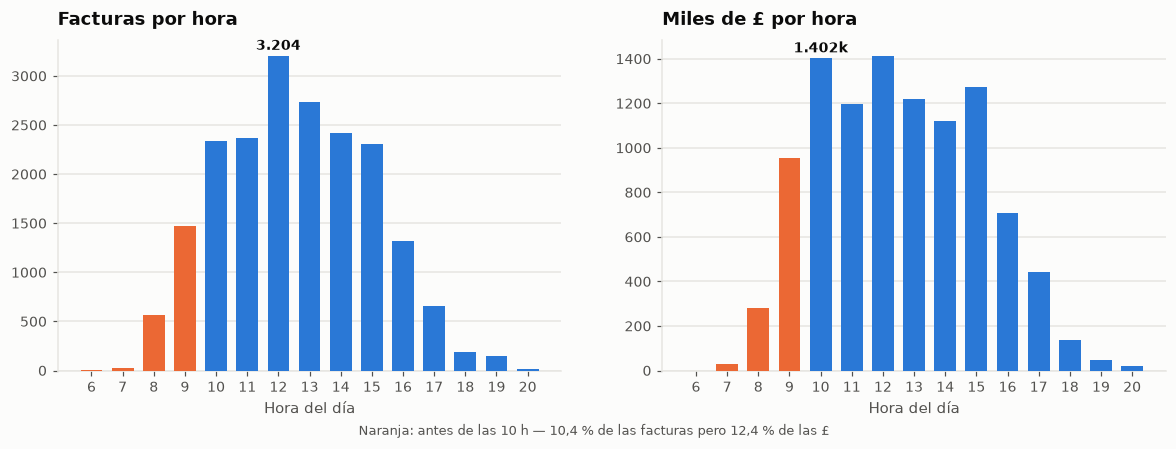

In [27]:
horas = fact.groupby('Hora').agg(Facturas=('Importe', 'size'),
                                 Miles=('Importe', 'sum'))
horas['Miles'] /= 1000

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, col, titulo in [(axes[0], 'Facturas', 'Facturas por hora'),
                        (axes[1], 'Miles', 'Miles de £ por hora')]:
    colores = [NARANJA if h < 10 else AZUL for h in horas.index]
    ax.bar(horas.index, horas[col], color=colores, width=0.7, zorder=3)
    ax.set_xticks(horas.index)
    ax.grid(axis='y', zorder=0)
    ax.set_title(titulo)
axes[0].annotate(miles(horas.loc[12, 'Facturas']), (12, horas.loc[12, 'Facturas']),
                 xytext=(0, 4), textcoords='offset points', ha='center',
                 fontsize=9, color=TINTA, fontweight='bold')
axes[1].annotate(f"{miles(horas.loc[10, 'Miles'])}k", (10, horas.loc[10, 'Miles']),
                 xytext=(0, 4), textcoords='offset points', ha='center',
                 fontsize=9, color=TINTA, fontweight='bold')
for ax in axes:
    ax.set_xlabel('Hora del día')
fig.text(0.5, -0.04, 'Naranja: antes de las 10 h — 10,4 % de las facturas pero 12,4 % de las £',
         ha='center', fontsize=8.5, color=TINTA2)
fig.savefig(FIG / 'e4_horas.png'); plt.show()

**Lectura de la gráfica:** los dos paneles pican al mediodía, pero **no pesan igual**. La franja naranja (antes de las 10 h) emite solo el 10,4 % de las facturas y sin embargo aporta el 12,4 % de las £; las 9 h en particular concentran el 7,4 % de las facturas pero el 9,3 % de las £. Y las 10 h casi empatan a las 12 h en £ (13,7 % vs 13,8 %) con bastantes menos facturas. Es la confirmación visual del hallazgo del paso 3: **la mañana es horario de pedidos mayoristas grandes**; el mediodía, de volumen de pedidos típicos. Para la matriz de clientes, el tamaño de pedido quedará capturado por `ticket_promedio` e `items_por_factura`.

## 4.2 Qué se vende: los dos rankings no coinciden

"Producto estrella" significa dos cosas distintas: el que más **unidades** rota y el que más **£** factura. Antes de rankear se excluyen las dos líneas de los pedidos fantasma (facturas 581483 y 541431, canceladas a los minutos — paso 2): de lo contrario `PAPER CRAFT , LITTLE BIRDIE` sería el nº 1 por unidades del año con **una única venta**… que fue cancelada.

Catálogo: 3.906 productos · el top 100 concentra 31.5 % de las £ · 841 productos (21.5 % del catálogo) hacen el 80 %


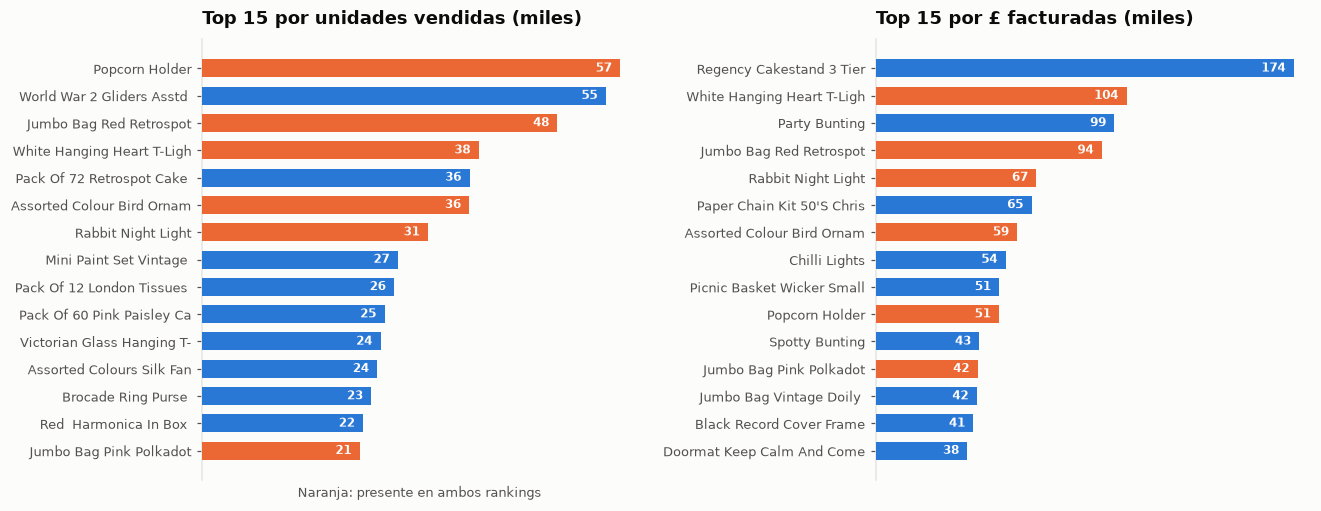

In [28]:
ventas_sf = ventas[~ventas['Factura'].isin(['581483', '541431'])]  # sin fantasmas
prod = (ventas_sf.groupby('CodProducto')
        .agg(Descripcion=('Descripcion', lambda s: s.mode().iat[0]),
             Unidades=('Cantidad', 'sum'),
             Libras=('ValorTotal', 'sum')))
top_u = prod.nlargest(15, 'Unidades')
top_l = prod.nlargest(15, 'Libras')
en_ambos = set(top_u.index) & set(top_l.index)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, top, col, titulo in [(axes[0], top_u, 'Unidades', 'Top 15 por unidades vendidas (miles)'),
                             (axes[1], top_l, 'Libras', 'Top 15 por £ facturadas (miles)')]:
    y = np.arange(len(top))[::-1]
    colores = [NARANJA if c in en_ambos else AZUL for c in top.index]
    vals = top[col] / 1000
    ax.barh(y, vals, color=colores, height=0.66, zorder=3)
    ax.set_yticks(y, [d.title()[:26] for d in top['Descripcion']], fontsize=8.5)
    for yi, v in zip(y, vals):
        ax.text(v - vals.max() * 0.02, yi, miles(v), va='center', ha='right',
                fontsize=8, color=SUP, fontweight='bold')
    ax.set_xticks([])
    ax.spines['bottom'].set_visible(False)
    ax.set_xlim(0, vals.max() * 1.04)
    ax.set_title(titulo)
fig.subplots_adjust(wspace=0.55)
axes[0].set_xlabel('Naranja: presente en ambos rankings', fontsize=8.5)

acum = prod['Libras'].sort_values(ascending=False).cumsum() / prod['Libras'].sum()
print(f'Catálogo: {miles(len(prod))} productos · el top 100 concentra '
      f'{100 * acum.iloc[99]:.1f} % de las £ · {(acum < 0.8).sum() + 1} productos '
      f'({100 * ((acum < 0.8).sum() + 1) / len(prod):.1f} % del catálogo) hacen el 80 %')
fig.savefig(FIG / 'e4_productos.png'); plt.show()

**Lectura de la gráfica:** rotación y facturación son negocios distintos — **solo 6 de 15 productos aparecen en ambos rankings** (naranja). El nº 1 por unidades es el `POPCORN HOLDER` (56.898 uds que apenas facturan £51k) y el nº 1 por £ es el `REGENCY CAKESTAND 3 TIER` (£174k con solo 13.851 uds). El surtido retrata el negocio: bolsas jumbo, portavelas, moldes de repostería, adornos — **bazar de regalo de precio bajo comprado por docenas**, coherente con clientes que revenden. La concentración de catálogo es moderada (ver salida): no hay un producto que "haga" la tienda, hay un surtido largo — por eso la matriz de clientes captura la **amplitud** (`n_productos_distintos`) y no productos individuales.

## 4.3 A quién: los mercados fuera de UK

UK concentra el 85,1 % de las £ (paso 3). Los otros 37 países importan menos por volumen que por **tipo de cliente**: aquí se mide cuánto factura cada mercado y cuántos clientes reales hay detrás.

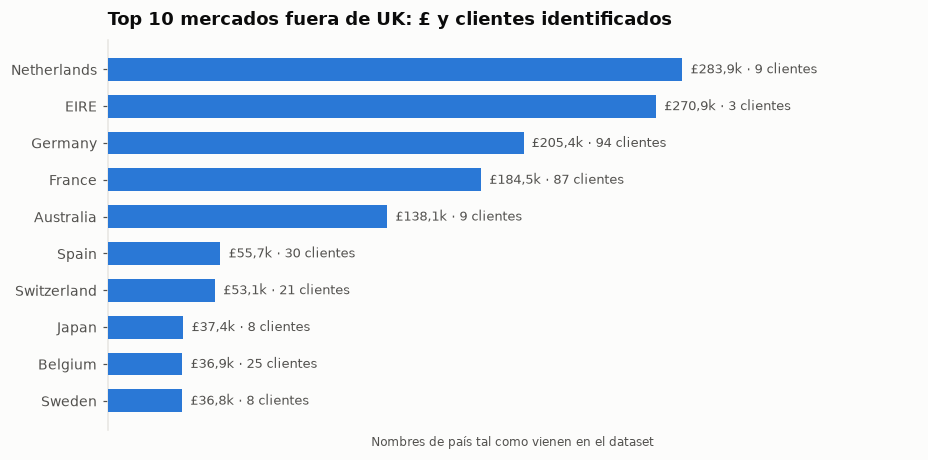

Ticket mediano por factura — UK: £300 (17,901 facturas)  ·  extranjero: £385 (1,872 facturas)


In [29]:
ext = ventas[ventas['Pais'] != 'United Kingdom']
paises = (ext.groupby('Pais')
          .agg(Libras=('ValorTotal', 'sum'), Clientes=('IdCliente', 'nunique'))
          .nlargest(10, 'Libras'))

fig, ax = plt.subplots(figsize=(9.5, 4.6))
y = np.arange(len(paises))[::-1]
ax.barh(y, paises['Libras'] / 1000, color=AZUL, height=0.62, zorder=3)
ax.set_yticks(y, paises.index)
for yi, v, c in zip(y, paises['Libras'] / 1000, paises['Clientes']):
    ax.text(v + 4, yi, f'£{miles(v, 1)}k · {c} clientes', va='center',
            fontsize=8.5, color=TINTA2)
ax.set_xticks([])
ax.spines['bottom'].set_visible(False)
ax.set_xlim(0, 400)
ax.set_xlabel('Nombres de país tal como vienen en el dataset', fontsize=8)
ax.set_title('Top 10 mercados fuera de UK: £ y clientes identificados')
fig.savefig(FIG / 'e4_paises.png'); plt.show()

pais_fact = ventas.groupby('Factura')['Pais'].first()
es_uk = pais_fact == 'United Kingdom'
print(f"Ticket mediano por factura — UK: £{fact.loc[es_uk, 'Importe'].median():,.0f} "
      f"({es_uk.sum():,} facturas)  ·  extranjero: £{fact.loc[~es_uk, 'Importe'].median():,.0f} "
      f"({(~es_uk).sum():,} facturas)")

**Lectura de la gráfica:** hay dos tipos de mercado exterior. **Alemania (94 clientes) y Francia (87)** son mercados reales con cartera; **Holanda (9), Australia (9), Japón (8) y EIRE (3)** son carteras mínimas donde, como mostró el paso 3, uno o dos mayoristas concentran casi todo (NL 98,3 %, AU 90,2 %). Además, la factura extranjera media es **1,29× más grande** que la de UK (mediana £385 vs £300) y el anonimato es un fenómeno exclusivamente británico: el extranjero está identificado casi al 100 % (el peor caso es EIRE con 5,1 % de £ sin ID). **Implicación para PG1:** fuera de UK el cliente típico ya es mayorista puro; el país no será *feature*, pero el tamaño de pedido sí.

## 4.4 De qué tamaño: ticket por factura y cantidad por línea

Las dos distribuciones que definen la "escala" de un pedido, en escala logarítmica porque sus colas se extienden **3–4 órdenes de magnitud**.

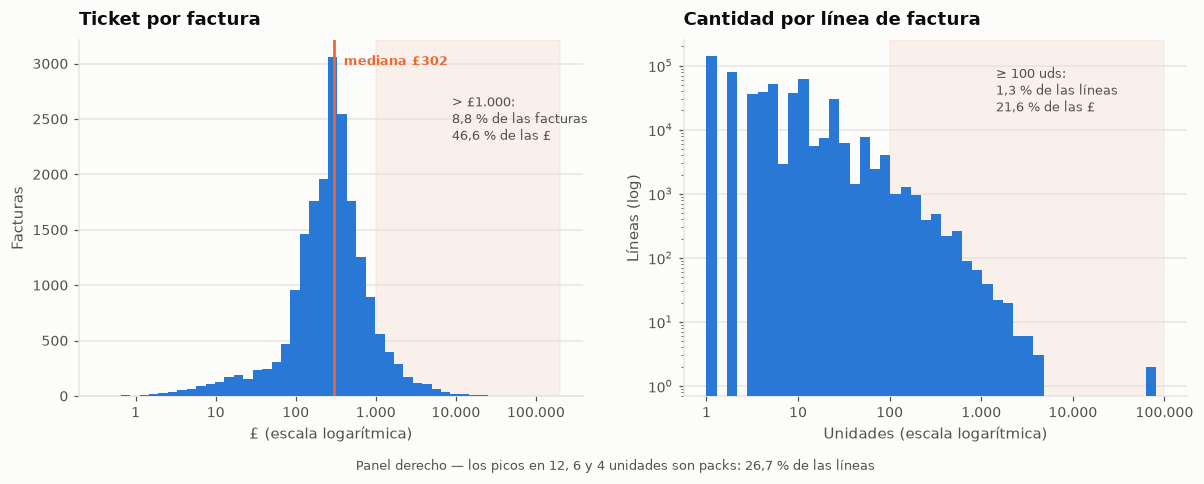

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

# --- Ticket por factura -----------------------------------------------------
ax = axes[0]
med = fact['Importe'].median()
ax.hist(np.log10(fact['Importe']), bins=48, color=AZUL, zorder=3)
ax.axvline(np.log10(med), color=NARANJA, lw=1.8, zorder=4)
ax.text(np.log10(med) + 0.12, 0.93, f'mediana £{miles(med)}',
        transform=ax.get_xaxis_transform(), fontsize=8.5,
        color=NARANJA, fontweight='bold')
ax.axvspan(3, 5.3, color=NARANJA, alpha=0.08, zorder=0)
ax.text(0.74, 0.72, '> £1.000:\n8,8 % de las facturas\n46,6 % de las £',
        transform=ax.transAxes, fontsize=8.5, color=TINTA2)
ax.set_xticks([0, 1, 2, 3, 4, 5], ['1', '10', '100', '1.000', '10.000', '100.000'])
ax.grid(axis='y', zorder=0)
ax.set_title('Ticket por factura')
ax.set_xlabel('£ (escala logarítmica)')
ax.set_ylabel('Facturas')

# --- Cantidad por línea -----------------------------------------------------
ax = axes[1]
ax.hist(np.log10(ventas['Cantidad'].clip(lower=1)), bins=44, color=AZUL, zorder=3)
ax.set_yscale('log')
ax.axvspan(2, 5, color=NARANJA, alpha=0.08, zorder=0)
ax.text(0.62, 0.8, '≥ 100 uds:\n1,3 % de las líneas\n21,6 % de las £',
        transform=ax.transAxes, fontsize=8.5, color=TINTA2)
ax.set_ylim(0.7, None)
ax.set_xticks([0, 1, 2, 3, 4, 5], ['1', '10', '100', '1.000', '10.000', '100.000'])
ax.grid(axis='y', zorder=0)
ax.set_title('Cantidad por línea de factura')
ax.set_xlabel('Unidades (escala logarítmica)')
fig.text(0.5, -0.05, 'Panel derecho — los picos en 12, 6 y 4 unidades son packs: 26,7 % de las líneas', ha='center', fontsize=8.5, color=TINTA2)
ax.set_ylabel('Líneas (log)')
fig.savefig(FIG / 'e4_tamanos.png'); plt.show()

**Lectura de la gráfica:**

- **Ticket:** forma log-normal con mediana £302 y media £518 (1,7×, la cola manda). El dato de negocio está en la zona naranja: **el 8,8 % de las facturas que superan £1.000 concentra el 46,6 % de toda la facturación** — casi la mitad del negocio viene de 1 de cada 11 pedidos.
- **Cantidad por línea:** mediana 4 y moda 1, pero con picos nítidos en 12, 6 y 4 unidades (26,7 % de las líneas): **se compra por packs**, la firma del mayorista. En la cola, el 1,3 % de líneas con ≥100 unidades aporta el 21,6 % de las £.

Los dos extremos conviven en el mismo dataset: compra tipo minorista (1–2 unidades) y reposición mayorista por cientos. Esa mezcla es exactamente lo que **PG1** pide segmentar.

## 4.5 Correlaciones a nivel factura

¿Qué hace grande a una factura: muchas líneas, muchas unidades o artículos caros? Se usa **Spearman** (correlación de rangos) porque las colas destrozan a Pearson: en `Importe`~`Líneas` Pearson da 0,24 contra **0,55** de Spearman, y en `Cantidad`~`PrecioUnitario` (nivel línea) Pearson da −0,02 contra **−0,41**. Con colas de 4 órdenes de magnitud, Pearson mide a los outliers, no a los datos.

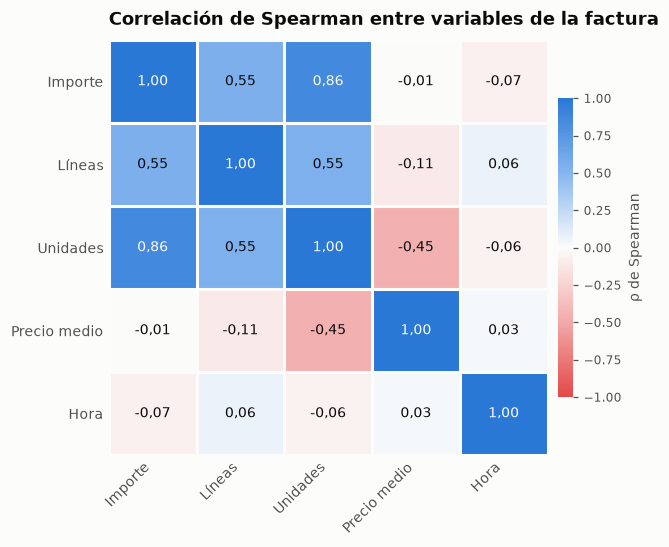

In [31]:
fact['Unidades'] = ventas.groupby('Factura')['Cantidad'].sum()
fact['PrecioMedio'] = fact['Importe'] / fact['Unidades']

corr_fact = (fact[['Importe', 'Lineas', 'Unidades', 'PrecioMedio', 'Hora']]
             .corr(method='spearman'))
corr_fact.index = corr_fact.columns = ['Importe', 'Líneas', 'Unidades',
                                       'Precio medio', 'Hora']

CM_DIV = mpl.colors.LinearSegmentedColormap.from_list(
    'div_corr', [ROJO, '#f2a9a8', SUP, '#86b6ef', AZUL])

def mapa_corr(tabla, ax, tam=9):
    # Diverging: rojo = negativa, azul = positiva, superficie = 0
    im = ax.imshow(tabla.values, cmap=CM_DIV, vmin=-1, vmax=1, aspect='auto')
    cb = ax.figure.colorbar(im, ax=ax, shrink=0.72, pad=0.02)
    cb.set_label('ρ de Spearman', fontsize=9, color=TINTA2)
    cb.ax.tick_params(labelsize=8, colors=TINTA2)
    cb.outline.set_visible(False)
    ax.set_xticks(range(tabla.shape[1]), tabla.columns, fontsize=9,
                  rotation=45, ha='right')
    ax.set_yticks(range(tabla.shape[0]), tabla.index, fontsize=9)
    ax.set_xticks(np.arange(-0.5, tabla.shape[1]), minor=True)
    ax.set_yticks(np.arange(-0.5, tabla.shape[0]), minor=True)
    ax.grid(which='minor', color=SUP, linewidth=2)
    ax.tick_params(which='both', length=0)
    for lado in ax.spines.values():
        lado.set_visible(False)
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            v = tabla.values[i, j]
            etq = f'{v:.2f}'.replace('.', ',')
            etq = '0,00' if etq == '-0,00' else etq
            ax.text(j, i, etq, ha='center', va='center',
                    fontsize=tam, color=SUP if abs(v) > 0.75 else TINTA)

fig, ax = plt.subplots(figsize=(6.2, 4.9))
mapa_corr(corr_fact, ax)
ax.set_title('Correlación de Spearman entre variables de la factura')
fig.savefig(FIG / 'e4_correlacion.png'); plt.show()

**Lectura de la gráfica:**

- **El ticket lo hace el volumen, no el precio:** `Importe`~`Unidades` = 0,86 e `Importe`~`Líneas` = 0,55, mientras `Importe`~`Precio medio` ≈ 0. Nadie factura mucho comprando caro: se factura mucho comprando **mucho**.
- **Barato a granel:** `Unidades`~`Precio medio` = −0,45 — cuanto más grande el pedido, más baratos los artículos. Física de mayorista.
- **La hora es independiente de todo** (|ρ| ≤ 0,07): en rangos, la hora no ordena el tamaño del pedido. Los pedidos matutinos "grandes" de 4.1 son un efecto de *media* (pocos pedidos enormes), no del pedido típico — consistente con la mediana casi plana del paso 3.

Aviso para el paso 5: esta redundancia (importe ≈ unidades ≈ líneas) reaparecerá entre las *features* de cliente, y es el argumento del PCA del paso 8.

## 4.6 Conclusiones del paso 4

| Pregunta | Hallazgo | Implicación |
|---|---|---|
| **¿Qué se vende?** | Bazar de regalo de precio bajo; los rankings de unidades y £ solo coinciden en 6/15; catálogo largo sin producto dominante | El producto individual no entra en la matriz; la **amplitud** sí (`n_productos_distintos`) |
| **¿A quién?** | Alemania/Francia = mercados con cartera; NL/AU/EIRE = 1–3 mayoristas; ticket extranjero 1,29× el de UK | `Pais` no será *feature* (paso 3); el tamaño de pedido sí |
| **¿De qué tamaño?** | 8,8 % de facturas >£1.000 = 46,6 % de las £; packs de 12/6/4 = 26,7 % de las líneas | Coexisten minoristas y mayoristas → materia prima de **PG1** |
| **¿Qué correlaciona?** | Importe~Unidades 0,86; el precio medio no explica nada; Pearson engañado por colas (0,24 vs 0,55) | **Spearman** para diagnósticos y **log1p antes de escalar** (paso 7) |
| **Fantasmas** | Distorsionan hasta un ranking de productos (nº 1 por unidades con una sola venta) | Su detección formal es el paso 6 (**PG2**) |

---
# 5. Ingeniería de características: la matriz de clientes

La regla de oro de la actividad: **una fila = un cliente, cada columna = un rasgo comparable de su comportamiento**. Todo lo aprendido en los pasos 1–4 se condensa en 12 *features*, combinando el **enfoque A** (agregados por cliente) con el **enfoque C** (proporciones):

| Feature | Definición | Qué pregunta responde |
|---|---|---|
| `recencia` | días desde la última compra hasta el **2011-12-10** | ¿Sigue activo? (**R** de RFM) |
| `frecuencia` | nº de facturas de compra | ¿Cuántas veces compra? (**F**) |
| `monetario` | gasto **neto**: compras − devoluciones | ¿Cuánto vale? (**M**) |
| `ticket_promedio` | monetario / frecuencia | ¿Pedidos grandes o chicos? |
| `items_por_factura` | unidades compradas / frecuencia | ¿Escala mayorista? |
| `n_productos_distintos` | códigos de producto distintos | ¿Amplitud de surtido? |
| `tasa_cancelacion` | facturas C / (facturas de compra + C) | ¿Fricción / devoluciones? |
| `antiguedad_dias` | días entre primera y última compra | ¿Relación larga o puntual? |
| `dias_entre_compras` | antigüedad / (frecuencia − 1); **centinela −1** si compró una sola vez | ¿Cadencia de recompra? |
| `prop_lun_mie` · `prop_jue_vie` · `prop_dom` | proporción de sus facturas en cada grupo de días | ¿Hábito semanal? |

Las tres primeras son el **RFM** clásico que exige la rúbrica; el resto lo extiende con tamaño, surtido, fricción y hábito. Dos decisiones heredadas: las proporciones son **por día** y no por franja horaria (el día discrimina mejor — paso 3), y la última se llama `prop_dom` y no `prop_sab_dom` porque **no existen sábados** en los datos (paso 2). Las cancelaciones entran dos veces a propósito: restando en `monetario` y como `tasa_cancelacion` (decisión del paso 1).

## 5.1 Construcción

Se parte del **dataset B** (`base`): artículos con cliente identificado y precio válido, cancelaciones incluidas y marcadas. Compras y devoluciones se agregan por separado y se combinan al final.

In [32]:
compras = base[~base['EsCancelacion']]
devol   = base[base['EsCancelacion']]
REF = pd.Timestamp('2011-12-10')          # día siguiente al último registro

# --- Agregados de compra por cliente ----------------------------------------
g = compras.groupby('IdCliente')
clientes_df = pd.DataFrame({
    'recencia':              (REF - g['FechaHora'].max()).dt.days,
    'frecuencia':            g['Factura'].nunique(),
    'bruto':                 g['ValorTotal'].sum(),
    'unidades':              g['Cantidad'].sum(),
    'n_productos_distintos': g['CodProducto'].nunique(),
    'antiguedad_dias':       (g['FechaHora'].max() - g['FechaHora'].min()).dt.days,
})

# --- Devoluciones (ValorTotal negativo) -------------------------------------
devuelto = devol.groupby('IdCliente')['ValorTotal'].sum()
n_canc   = devol.groupby('IdCliente')['Factura'].nunique()
clientes_df['devuelto'] = devuelto.reindex(clientes_df.index).fillna(0)
clientes_df['n_canc']   = n_canc.reindex(clientes_df.index).fillna(0)

# --- Features derivadas ------------------------------------------------------
clientes_df['monetario']         = clientes_df['bruto'] + clientes_df['devuelto']
clientes_df['ticket_promedio']   = clientes_df['monetario'] / clientes_df['frecuencia']
clientes_df['items_por_factura'] = clientes_df['unidades'] / clientes_df['frecuencia']
clientes_df['tasa_cancelacion']  = (clientes_df['n_canc']
                                    / (clientes_df['frecuencia'] + clientes_df['n_canc']))
clientes_df['dias_entre_compras'] = np.where(
    clientes_df['frecuencia'] > 1,
    clientes_df['antiguedad_dias'] / (clientes_df['frecuencia'] - 1), -1)

# --- Proporciones por grupo de día (por factura, primera marca de tiempo) ---
fact_cli = (compras.sort_values('FechaHora')
                   .groupby('Factura')
                   .agg(IdCliente=('IdCliente', 'first'),
                        FechaHora=('FechaHora', 'first')))
grupo_dia = pd.cut(fact_cli['FechaHora'].dt.dayofweek, bins=[-1, 2, 4, 6],
                   labels=['prop_lun_mie', 'prop_jue_vie', 'prop_dom'])
clientes_df = clientes_df.join(
    pd.crosstab(fact_cli['IdCliente'], grupo_dia, normalize='index'))

FEATURES = ['recencia', 'frecuencia', 'monetario', 'ticket_promedio',
            'items_por_factura', 'n_productos_distintos', 'tasa_cancelacion',
            'antiguedad_dias', 'dias_entre_compras',
            'prop_lun_mie', 'prop_jue_vie', 'prop_dom']
clientes_df = clientes_df[FEATURES]

solo_devol = set(devol['IdCliente'].unique()) - set(compras['IdCliente'].unique())
print(f'Clientes en el dataset B        : {miles(base["IdCliente"].nunique())}')
print(f'Excluidos (solo devoluciones)   : {len(solo_devol)}')
print(f'clientes_df                     : {clientes_df.shape[0]} clientes × {clientes_df.shape[1]} features')
print(f'NaN totales                     : {clientes_df.isna().sum().sum()}')
print(f'Clientes con monetario ≤ 0      : {(clientes_df["monetario"] <= 0).sum()}'
      f'  (mínimo £{clientes_df["monetario"].min():,.2f})')
clientes_df.loc[[12346, 16446]]

Clientes en el dataset B        : 4.362
Excluidos (solo devoluciones)   : 28
clientes_df                     : 4334 clientes × 12 features
NaN totales                     : 0
Clientes con monetario ≤ 0      : 12  (mínimo £-141.48)


,recencia,frecuencia,monetario,ticket_promedio,items_por_factura,n_productos_distintos,tasa_cancelacion,antiguedad_dias,dias_entre_compras,prop_lun_mie,prop_jue_vie,prop_dom
IdCliente,,,,,,,,,,,,
12346,325,1,0.00,0.00,"74,215.00",1,0.50,0,-1.00,1.00,0.00,0.00
16446,0,2,2.90,1.45,"40,498.50",3,0.33,204,204.00,0.50,0.50,0.00


**Lectura de la construcción:** la matriz cumple la regla de la guía — **4.334 clientes × 12 features, cero NaN** — y las decisiones de borde quedan documentadas:

- **28 clientes excluidos** por tener *solo* devoluciones en la ventana (devuelven compras anteriores a dic-2010): sin ninguna compra no hay comportamiento que perfilar. Se reportan en el informe como caso límite.
- **12 clientes quedan con `monetario` ≤ 0** (2 negativos, mínimo −£141): devolvieron tanto o más de lo que compraron. Se **conservan** — son exactamente el tipo de cliente que PG3 quiere encontrar. El paso 7 usará `log1p` con recorte inferior en 0 y la información de devolución sobrevive en `tasa_cancelacion`.
- Las dos filas mostradas son los protagonistas de los pedidos fantasma, y enseñan algo importante: **el gasto neto los vuelve invisibles en RFM** (12346: monetario £0; 16446: £2,90), pero `items_por_factura` (74.215 y 40.499, los dos máximos de la matriz) y `tasa_cancelacion` (0,50 y 0,33) **los delatan**. La matriz no es solo RFM a propósito: cada extensión cubre un punto ciego.

## 5.2 Radiografía de la matriz

`describe()` con percentiles altos: en un dataset mayorista la historia está en las colas.

In [33]:
radiografia = clientes_df.describe(percentiles=[.25, .5, .75, .9, .99]).T
radiografia.round(2)

,count,mean,std,min,25%,50%,75%,90%,99%,max
recencia,"4,334.00",92.23,100.18,0.00,17.00,50.00,142.00,263.00,368.00,373.00
frecuencia,"4,334.00",4.25,7.63,1.00,1.00,2.00,5.00,9.00,30.00,206.00
monetario,"4,334.00","1,908.03","8,291.08",-141.48,296.78,646.84,"1,600.84","3,449.39","17,049.10","278,778.02"
ticket_promedio,"4,334.00",368.19,464.57,-141.48,172.30,280.38,419.52,639.33,"1,934.18","13,206.50"
items_por_factura,"4,334.00",255.28,"1,316.38",1.00,92.52,161.00,271.98,421.18,"1,385.04","74,215.00"
n_productos_distintos,"4,334.00",61.43,85.31,1.00,16.00,35.00,77.00,142.70,353.67,"1,785.00"
tasa_cancelacion,"4,334.00",0.10,0.16,0.00,0.00,0.00,0.20,0.33,0.53,0.75
antiguedad_dias,"4,334.00",130.29,132.09,0.00,0.00,92.00,252.00,339.00,367.00,373.00
dias_entre_compras,"4,334.00",47.21,63.50,-1.00,-1.00,28.18,68.50,123.85,305.67,365.00
prop_lun_mie,"4,334.00",0.50,0.38,0.00,0.00,0.50,1.00,1.00,1.00,1.00


**Lectura de la tabla:** el **cliente mediano** compró por última vez hace 50 días, hizo 2 pedidos, gastó £647 netos con ticket de £280, se lleva 161 unidades por pedido y ha probado 35 productos distintos — un pequeño revendedor, no un consumidor final. Alrededor de esa mediana:

- **Colas brutales:** `monetario` tiene media £1.908 contra mediana £647 (desviación £8.291); los máximos son £278.778 (cliente 14646), 206 facturas (12748) y 74.215 items/factura (12346). Ninguna técnica de distancias funciona sobre esto sin transformar — argumento directo de los pasos 6 y 7.
- **Escalas incompatibles:** proporciones en [0, 1] conviviendo con £ de 5 cifras. Sin escalar, K-Means solo vería `monetario`.
- **Poblaciones marcadas:** 34,7 % compradores de una sola vez (los 1.505 del centinela −1), 34,7 % con al menos una cancelación, y **19,8 % dormidos** (recencia > 180 días).

## 5.3 Las distribuciones, de una mirada

Histogramas de las 12 features (eje Y logarítmico en las de cola larga). Es la justificación visual del `log1p` del paso 7.

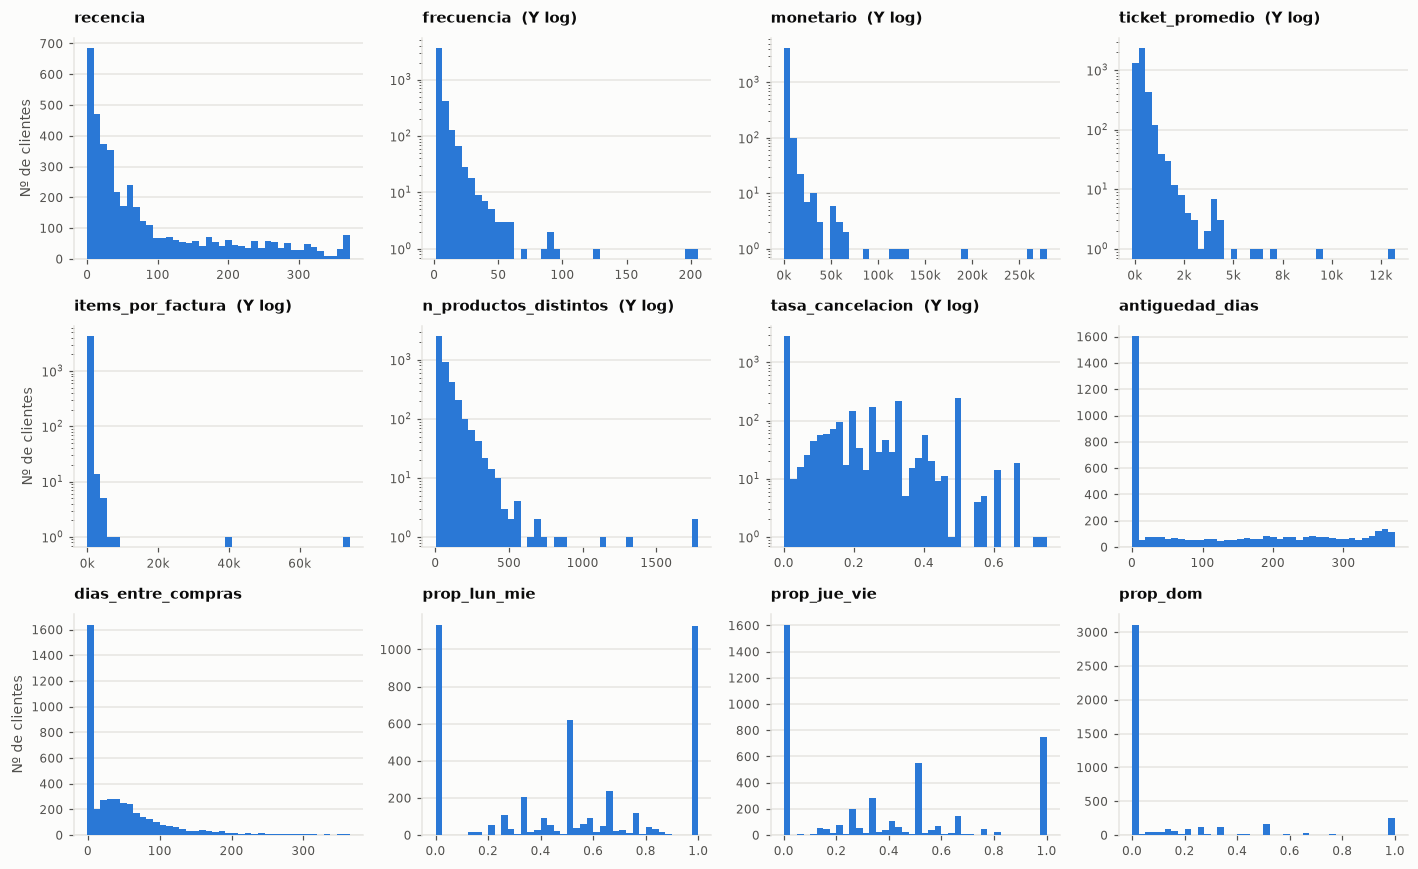

In [34]:
LOG_Y = {'frecuencia', 'monetario', 'ticket_promedio', 'items_por_factura',
         'n_productos_distintos', 'tasa_cancelacion'}

fig, axes = plt.subplots(3, 4, figsize=(13, 8))
for k, (ax, col) in enumerate(zip(axes.flat, FEATURES)):
    ax.hist(clientes_df[col], bins=40, color=AZUL, zorder=3)
    if col in LOG_Y:
        ax.set_yscale('log')
        ax.set_title(f'{col}  (Y log)', fontsize=10)
    else:
        ax.set_title(col, fontsize=10)
    if k % 4 == 0:
        ax.set_ylabel('Nº de clientes', fontsize=9)
    if clientes_df[col].max() > 8000:
        ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f'{v / 1000:.0f}k'))
    ax.grid(axis='y', zorder=0)
    ax.tick_params(labelsize=8)
fig.tight_layout()
fig.savefig(FIG / 'e5_distribuciones.png'); plt.show()

**Lectura de la gráfica:** cuatro patrones que condicionan los pasos siguientes:

1. **Colas extremas en las features de dinero y volumen:** la asimetría de `monetario` es 21,6, la de `ticket_promedio` 10,7 y la de `items_por_factura` 47,7. Tras `log1p` (con recorte inferior en 0 donde hay negativos) quedan en −0,04, −1,03 y −0,26: de colas inmanejables a distribuciones aproximadamente simétricas — la transformación del paso 7 queda justificada con números. `frecuencia` es la que peor responde (de 11,95 baja a 1,21): es un conteo entero donde el 34,7 % vale exactamente 1.
2. **El pico artificial en −1** de `dias_entre_compras`: los 1.505 compradores únicos forman una barra idéntica que no es comportamiento sino centinela. Se documenta como limitación y se vigila en los pasos 7–8.
3. **`tasa_cancelacion` es *zero-inflated***: 65,3 % de ceros exactos — `log1p` no arregla eso; la feature vale por separar "cancela" de "no cancela".
4. `recencia` y `antiguedad_dias` son las más sanas (asimetría moderada, rango acotado por la ventana de 373 días).

## 5.4 Correlación entre features: las candidatas al PCA

Spearman otra vez (las colas siguen ahí). Lo que se busca no es "qué correlaciona con qué" sino **cuántas dimensiones reales** hay en estas 12 columnas.

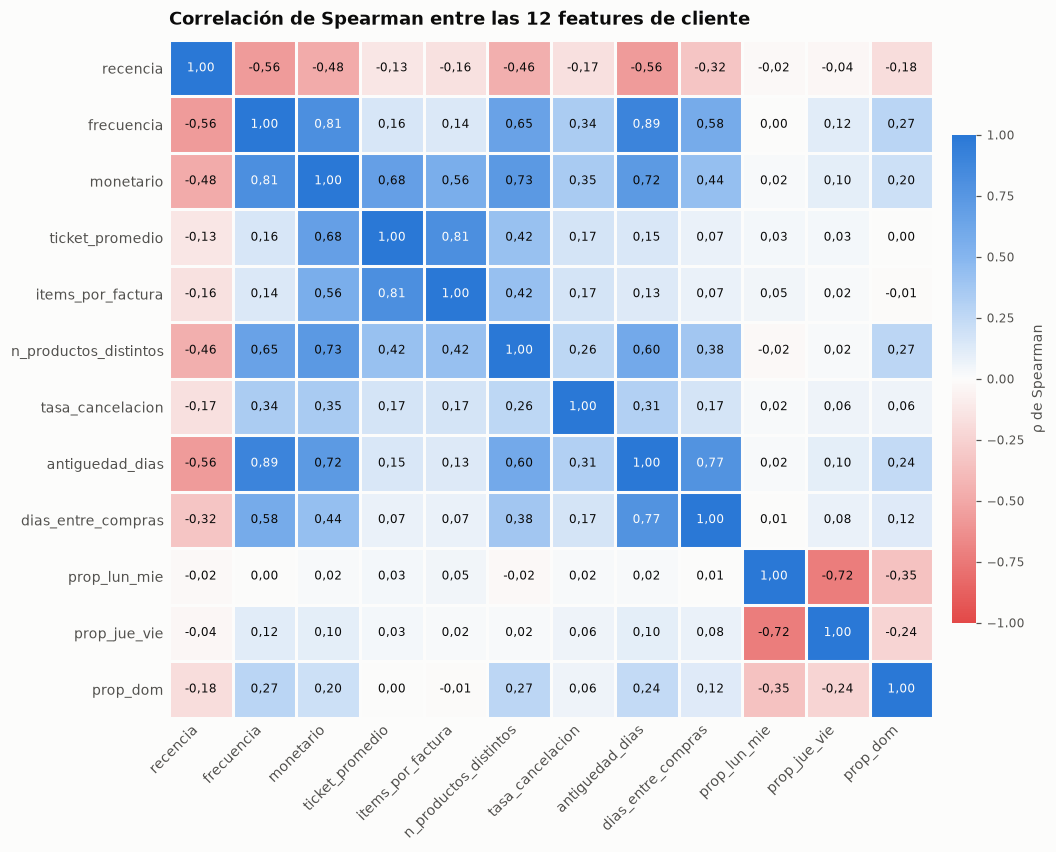

In [35]:
corr_cli = clientes_df.corr(method='spearman')

fig, ax = plt.subplots(figsize=(10.8, 8))
mapa_corr(corr_cli, ax, tam=8)
ax.set_title('Correlación de Spearman entre las 12 features de cliente')
fig.savefig(FIG / 'e5_correlacion.png'); plt.show()

**Lectura de la gráfica:** las 12 features se organizan en unos pocos ejes latentes — exactamente lo que el PCA del paso 8 va a formalizar:

- **Eje "intensidad de la relación":** `frecuencia`~`antiguedad_dias` **0,89**, `frecuencia`~`monetario` **0,81**, `monetario`~`n_productos_distintos` 0,73, `monetario`~`antiguedad_dias` 0,72. Quien compra seguido, lleva tiempo, gasta más y prueba más surtido: una sola dimensión de valor.
- **Eje "tamaño del pedido":** `ticket_promedio`~`items_por_factura` **0,81**, casi ortogonal a la frecuencia (0,16 y 0,14): comprar *mucho por pedido* y comprar *seguido* son cosas independientes — dos estrategias mayoristas distintas.
- **`recencia` en negativo con casi todo** (−0,56 con frecuencia, −0,48 con monetario): los clientes valiosos están activos. Es el eje R.
- **Las proporciones por día viven aparte** (|ρ| ≤ 0,27 con el resto) y entre sí son negativas por construcción — **suman exactamente 1**, la covarianza es singular y en el PCA una componente tendrá varianza 0. Se decidirá allí (basta con que el PCA la deje morir en la última componente).

Conclusión: hay ~4–5 dimensiones reales en 12 columnas. El PCA tiene mucho que comprimir.

## 5.5 Conclusiones del paso 5

| Resultado | Detalle | Hacia dónde apunta |
|---|---|---|
| **Matriz final `clientes_df`** | **4.334 × 12, cero NaN**, RFM completo + tamaño, surtido, fricción y hábito | Insumo directo de los pasos 6 (anomalías), 7 (escalado) y 8 (PCA) |
| **28 clientes solo-devolución** | Excluidos: sin compra en la ventana no hay perfil | Se reportan como caso límite en el informe |
| **12 clientes con monetario ≤ 0** | Devolvieron ≥ lo comprado; mínimo −£141 (17548) | Se conservan (candidatos PG3); `log1p` con recorte en 0 (paso 7) |
| **Centinela −1** | 1.505 compradores únicos (34,7 %) en `dias_entre_compras` | Pico artificial documentado; vigilar su efecto en distancias (pasos 7–8) |
| **Proporciones suman 1** | Colinealidad exacta entre las 3 `prop_*` | Una componente de varianza 0 en PCA (paso 8) |
| **Los fantasmas son detectables** | 12346 y 16446: invisibles en RFM neto, extremos en `items_por_factura` y `tasa_cancelacion` | El Isolation Forest del paso 6 debe usar **todas** las features, no solo RFM (**PG3**) |

---
# 6. Detección de anomalías — antes de escalar y clusterizar

Regla de la guía: las anomalías se detectan **antes** del escalado y del clustering, por dos razones: los extremos distorsionarían el `StandardScaler` (medias y desviaciones infladas) y K-Means es muy sensible a outliers. Se usa **Isolation Forest** en dos niveles, cada uno respondiendo una pregunta guía:

- **Nivel transacción → PG2:** ¿hay facturas anómalas?
- **Nivel cliente → PG3:** ¿hay clientes atípicos? Los que lo sean quedan fuera del clustering (`clientes_clean`) y se perfilan aparte en el paso 12.

Isolation Forest no requiere escalado (es un método de árboles: las particiones son invariantes a transformaciones monótonas), por eso puede correr sobre las features crudas.

## 6.1 Nivel transacción (PG2): barrido de `contamination`

`contamination` fija qué fracción de los datos se declara anómala — es una **decisión**, no un resultado. Se prueba con 1 %, 2 % y 5 % sobre la tabla `fact` (19.773 facturas con importe, líneas, unidades, precio medio y hora) y se elige mirando **qué tipo de factura agrega cada nivel**.

In [36]:
from sklearn.ensemble import IsolationForest

X_fact = fact[['Importe', 'Lineas', 'Unidades', 'PrecioMedio', 'Hora']]

barrido = {}
for cont in [0.01, 0.02, 0.05]:
    iso = IsolationForest(n_estimators=300, contamination=cont, random_state=SEED)
    barrido[cont] = iso.fit_predict(X_fact) == -1          # True = anómala

tabla_cont = pd.DataFrame([{
    'contamination': c,
    'Facturas': m.sum(),
    '% de las £': 100 * fact.loc[m, 'Importe'].sum() / fact['Importe'].sum(),
    'Mediana £ anóm.': fact.loc[m, 'Importe'].median(),
    'Mediana uds anóm.': fact.loc[m, 'Unidades'].median(),
    'Mediana £ norm.': fact.loc[~m, 'Importe'].median(),
} for c, m in barrido.items()]).set_index('contamination').round(1)
display(tabla_cont)

print('Conjuntos anidados (1% ⊂ 2% ⊂ 5%):',
      (barrido[0.01] <= barrido[0.02]).all() and (barrido[0.02] <= barrido[0.05]).all())
son_fantasma = fact.index.isin(['581483', '541431'])
print('Pedidos fantasma marcados en los tres niveles:',
      all(m[son_fantasma].all() for m in barrido.values()))

# Elección justificada en la lectura: 2 %
fact['EsAnomala'] = barrido[0.02]
sin_id = fact.loc[fact['EsAnomala'], 'IdCliente'].isna().mean()
print(f"\nElegido contamination=0.02 → {fact['EsAnomala'].sum()} facturas anómalas "
      f"({100 * sin_id:.1f} % sin IdCliente)")
fact[fact['EsAnomala']].nlargest(5, 'Importe')[['FechaHora', 'IdCliente', 'Importe', 'Unidades', 'Lineas']]

,Facturas,% de las £,Mediana £ anóm.,Mediana uds anóm.,Mediana £ norm.
contamination,,,,,
0.01,198,18.00,"5,906.90","2,145.00",301.10
0.02,396,24.30,"4,350.60","1,640.50",300.00
0.05,989,34.70,"2,242.30",947.00,292.70


Conjuntos anidados (1% ⊂ 2% ⊂ 5%): True
Pedidos fantasma marcados en los tres niveles: True

Elegido contamination=0.02 → 396 facturas anómalas (46.2 % sin IdCliente)


,FechaHora,IdCliente,Importe,Unidades,Lineas
Factura,,,,,
581483,2011-12-09 09:15:00,"16,446.00","168,469.60",80995,1
541431,2011-01-18 10:01:00,"12,346.00","77,183.60",74215,1
574941,2011-11-07 17:42:00,NaN,"52,940.94",14149,101
576365,2011-11-14 17:55:00,NaN,"50,653.91",13956,99
556444,2011-06-10 15:28:00,"15,098.00","38,970.00",60,1


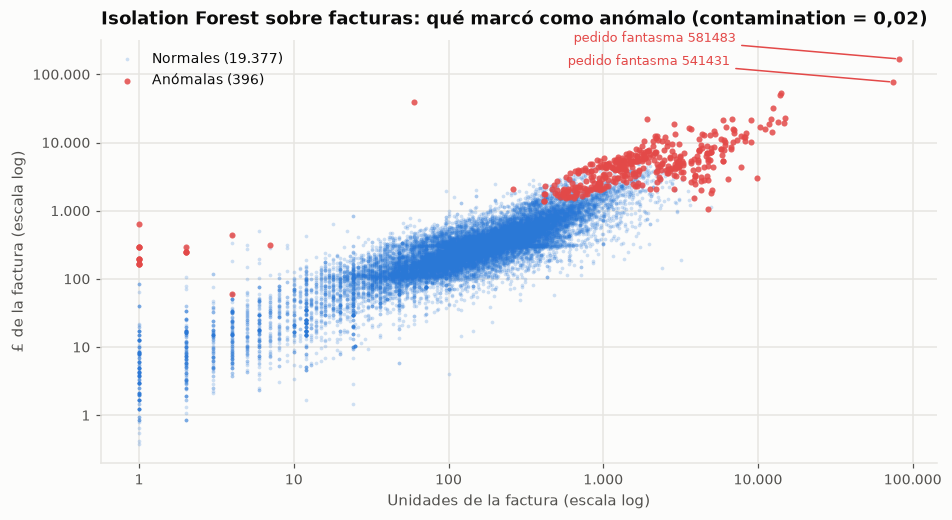

In [37]:
fig, ax = plt.subplots(figsize=(9.8, 5))
norm, anom = fact[~fact['EsAnomala']], fact[fact['EsAnomala']]
ax.scatter(np.log10(norm['Unidades']), np.log10(norm['Importe']), s=6, color=AZUL,
           alpha=0.22, lw=0, zorder=2, label=f'Normales ({miles(len(norm))})')
ax.scatter(np.log10(anom['Unidades']), np.log10(anom['Importe']), s=16, color=ROJO,
           alpha=0.85, lw=0, zorder=3, label=f'Anómalas ({miles(len(anom))})')
for f, dx in [('581483', -0.1), ('541431', -0.1)]:
    ax.annotate(f'pedido fantasma {f}',
                xy=(np.log10(fact.loc[f, 'Unidades']), np.log10(fact.loc[f, 'Importe'])),
                xytext=(np.log10(fact.loc[f, 'Unidades']) - 2.1,
                        np.log10(fact.loc[f, 'Importe']) + 0.25),
                fontsize=8.5, color=ROJO,
                arrowprops=dict(arrowstyle='-', color=ROJO, lw=1))
ax.set_xticks([0, 1, 2, 3, 4, 5], ['1', '10', '100', '1.000', '10.000', '100.000'])
ax.set_yticks([0, 1, 2, 3, 4, 5], ['1', '10', '100', '1.000', '10.000', '100.000'])
ax.grid(zorder=0)
ax.set_title('Isolation Forest sobre facturas: qué marcó como anómalo (contamination = 0,02)')
ax.set_xlabel('Unidades de la factura (escala log)')
ax.set_ylabel('£ de la factura (escala log)')
ax.legend(loc='upper left')
fig.savefig(FIG / 'e6_transacciones.png'); plt.show()

**Lectura del barrido y de la gráfica:** los tres conjuntos son **anidados** (cada nivel agrega facturas al anterior), así que la pregunta correcta es *qué agrega cada escalón*:

- **1 % (198 facturas):** mega-pedidos con mediana **£5.907** — por encima del P99 del ticket (£4.409). Extremos indiscutibles.
- **2 % (+198):** lo nuevo sigue siendo extremo real: mediana £2.850 y 1.069 unidades, **por encima del P95** (£1.508 y 810 uds). La cobertura de £ anómalo sube del 18,0 % al 24,3 %.
- **5 % (+593):** lo nuevo cae a mediana 531 unidades — **exactamente el P90**, es decir, la cola mayorista *legítima*. Marcar eso como anómalo sería confundir "cliente grande" con "transacción anómala".

**Decisión: `contamination = 0.02`** — se detiene justo antes de comerse la cola mayorista normal. Las **396 facturas anómalas** concentran el 24,3 % de las £; incluyen los dos pedidos fantasma (nº 1 y nº 2 del ranking) y un 46,2 % son de compradores **sin `IdCliente`** — el bloque anónimo que solo este análisis por transacción puede vigilar (por eso se conservó en el paso 1). Esta es la respuesta operativa a **PG2**.

## 6.2 Nivel cliente (PG3): atípicos y base depurada

Mismo modelo sobre la matriz `clientes_df` (4.334 × 12). Siguiendo el plan: `decision_function < 0` → cliente atípico; el resto forma **`clientes_clean`**, la base que pasa a los pasos 7–11.

In [38]:
iso_cli = IsolationForest(n_estimators=300, random_state=SEED)
iso_cli.fit(clientes_df)
puntaje = pd.Series(iso_cli.decision_function(clientes_df), index=clientes_df.index)

atipicos = clientes_df[puntaje < 0].copy()
clientes_clean = clientes_df[puntaje >= 0].copy()

print(f'Clientes atípicos (puntaje < 0): {len(atipicos)}  '
      f'({100 * len(atipicos) / len(clientes_df):.1f} % de la base)')
print(f'clientes_clean                 : {len(clientes_clean)}')
print(f'% del monetario total en atípicos: '
      f'{100 * atipicos["monetario"].sum() / clientes_df["monetario"].sum():.1f} %')

CLAVE = ['recencia', 'frecuencia', 'monetario', 'ticket_promedio',
         'items_por_factura', 'n_productos_distintos', 'tasa_cancelacion']
display(pd.DataFrame({'Atípicos (mediana)': atipicos[CLAVE].median(),
                      'Normales (mediana)': clientes_clean[CLAVE].median()}).round(2))

print('Los 5 atípicos con el puntaje más negativo:')
clientes_df.loc[puntaje.nsmallest(5).index,
                ['monetario', 'frecuencia', 'ticket_promedio', 'items_por_factura',
                 'tasa_cancelacion', 'recencia', 'n_productos_distintos']].round(1)

Clientes atípicos (puntaje < 0): 553  (12.8 % de la base)
clientes_clean                 : 3781
% del monetario total en atípicos: 53.8 %


,Atípicos (mediana),Normales (mediana)
recencia,26.00,53.00
frecuencia,4.00,2.00
monetario,"2,661.24",574.26
ticket_promedio,530.94,259.79
items_por_factura,320.45,149.67
n_productos_distintos,92.00,32.00
tasa_cancelacion,0.17,0.00


Los 5 atípicos con el puntaje más negativo:


,monetario,frecuencia,ticket_promedio,items_por_factura,tasa_cancelacion,recencia,n_productos_distintos
IdCliente,,,,,,,
14646,"278,778.00",72,"3,871.90","2,733.90",0.00,1,699
17511,"88,138.20",31,"2,843.20","2,082.20",0.30,2,453
12415,"123,638.20",20,"6,181.90","3,868.60",0.20,24,443
18102,"259,657.30",60,"4,327.60","1,068.70",0.00,0,150
14156,"113,685.80",54,"2,105.30","1,069.50",0.20,9,713


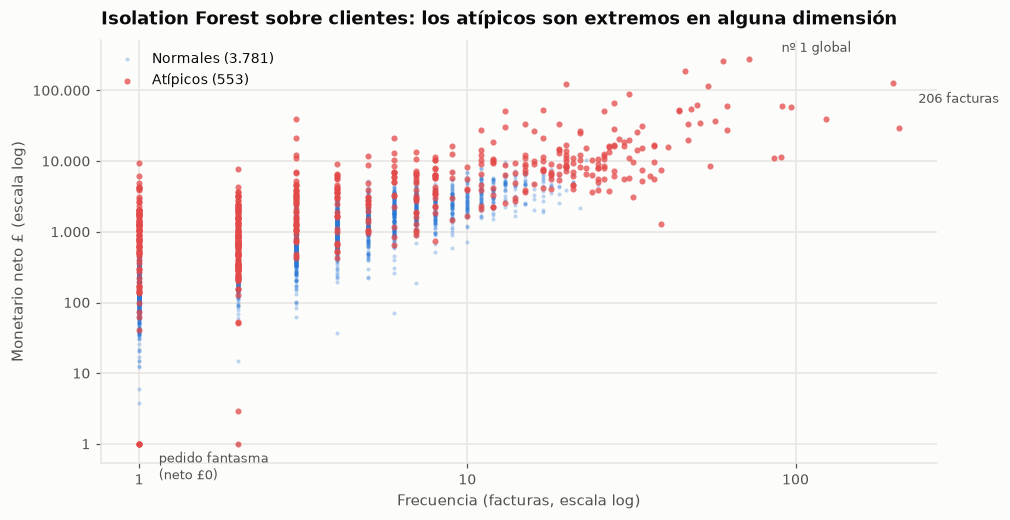

In [39]:
fig, ax = plt.subplots(figsize=(9.8, 5))
for datos, color, tam, alfa, etq in [
        (clientes_clean, AZUL, 7, 0.3, f'Normales ({miles(len(clientes_clean))})'),
        (atipicos, ROJO, 16, 0.75, f'Atípicos ({len(atipicos)})')]:
    ax.scatter(np.log10(datos['frecuencia']),
               np.log10(datos['monetario'].clip(lower=1)),
               s=tam, color=color, alpha=alfa, lw=0, zorder=3, label=etq)
for cid, etq, dx, dy in [(14646, 'nº 1 global', 0.1, 0.1), (12346, 'pedido fantasma\n(neto £0)', 0.06, -0.5),
                         (12748, '206 facturas', 0.06, 0.35)]:
    ax.annotate(etq, xy=(np.log10(clientes_df.loc[cid, 'frecuencia']),
                         np.log10(max(clientes_df.loc[cid, 'monetario'], 1))),
                xytext=(np.log10(clientes_df.loc[cid, 'frecuencia']) + dx,
                        np.log10(max(clientes_df.loc[cid, 'monetario'], 1)) + dy),
                fontsize=8.5, color=TINTA2)
ax.set_xticks([0, 1, 2], ['1', '10', '100'])
ax.set_yticks([0, 1, 2, 3, 4, 5], ['1', '10', '100', '1.000', '10.000', '100.000'])
ax.grid(zorder=0)
ax.set_title('Isolation Forest sobre clientes: los atípicos son extremos en alguna dimensión')
ax.set_xlabel('Frecuencia (facturas, escala log)')
ax.set_ylabel('Monetario neto £ (escala log)')
ax.legend(loc='upper left')
fig.savefig(FIG / 'e6_clientes.png'); plt.show()

**Lectura:** quedan marcados **553 clientes (12,8 %)** que concentran el **53,8 % del monetario total** — y eso es exactamente lo que debía pasar: en una base mayorista, los clientes más valiosos *son* estadísticamente atípicos. La tabla de medianas lo confirma: el atípico mediano compra el doble de veces (4 vs 2), gasta 4,6× más (£2.661 vs £574), lleva el triple de surtido (92 vs 32 productos) y — dato clave — **cancela** (tasa mediana 0,17 vs 0,00).

Dos familias conviven dentro de los atípicos, y las dos responden **PG3**:

1. **Ballenas legítimas:** 14646 (nº 1 global, £278.778), 18102, 12415, 17450, 12748 (206 facturas), 14911. No son errores: son clientes que necesitan gestión individual, no segmento.
2. **Anómalos de comportamiento:** 12346 y 16446 (los pedidos fantasma — detectados pese a tener monetario ≈ £0, gracias a `items_por_factura` y `tasa_cancelacion`, como anticipó el paso 5), 17548 (devolvió más de lo que compró) y 17511 (tasa de cancelación 0,31 con ticket alto).

La depuración **no borra a nadie**: los 553 se perfilan aparte en el paso 12. El clustering de los pasos 7–11 corre sobre los **3.781 de `clientes_clean`**, donde K-Means puede encontrar estructura sin que las ballenas arrastren los centroides.

---
# 7. Escalamiento

Las 12 features mezclan £ de cinco cifras con proporciones en [0, 1]: sin escalar, cualquier distancia euclidiana sería solo `monetario`. Dos pasos, ambos justificados con los números del 5.3:

1. **`log1p`** en las cinco features de cola larga (`frecuencia`, `monetario`, `ticket_promedio`, `items_por_factura`, `n_productos_distintos`), con recorte inferior en 0 para `monetario` y `ticket_promedio` (un cliente de `clientes_clean` quedó con neto −£96; `log1p` de valores ≤ −1 no existe).
2. **`StandardScaler`** para llevar todo a media 0 y desviación 1.

In [40]:
from sklearn.preprocessing import StandardScaler

LOG1P = ['frecuencia', 'monetario', 'ticket_promedio',
         'items_por_factura', 'n_productos_distintos']
Xt = clientes_clean[FEATURES].copy()
Xt[['monetario', 'ticket_promedio']] = Xt[['monetario', 'ticket_promedio']].clip(lower=0)
Xt[LOG1P] = np.log1p(Xt[LOG1P])

esc = StandardScaler()
X_esc = pd.DataFrame(esc.fit_transform(Xt), index=Xt.index, columns=Xt.columns)

print(f'Matriz escalada: {X_esc.shape[0]} clientes × {X_esc.shape[1]} features')
X_esc.describe().loc[['mean', 'std', 'min', 'max']].T.round(2)

Matriz escalada: 3781 clientes × 12 features


,mean,std,min,max
recencia,0.00,1.00,-0.95,2.78
frecuencia,0.00,1.00,-0.99,3.42
monetario,-0.00,1.00,-5.62,2.56
ticket_promedio,-0.00,1.00,-7.94,2.80
items_por_factura,0.00,1.00,-5.20,3.25
n_productos_distintos,-0.00,1.00,-2.58,2.19
tasa_cancelacion,-0.00,1.00,-0.57,4.32
antiguedad_dias,0.00,1.00,-0.94,2.00
dias_entre_compras,0.00,1.00,-0.79,5.54
prop_lun_mie,0.00,1.00,-1.37,1.26


**Lectura:** media ≈ 0 y desviación ≈ 1 en las 12 columnas — la salida que pide la guía. Nótese que los mínimos y máximos ya no son monstruosos (típicamente entre −2 y +5): el `log1p` hizo su trabajo con las colas y ninguna feature domina la distancia. El centinela −1 de `dias_entre_compras` queda a −0,8 desviaciones: no distorsiona como outlier, aunque sigue siendo un pico artificial documentado.

---
# 8. PCA: cuántas dimensiones reales hay

El 5.4 mostró bloques de features muy correlacionadas (ρ hasta 0,89): hay menos dimensiones reales que columnas. El PCA las formaliza y de paso resuelve la colinealidad exacta de las proporciones. Criterio de corte: **el menor número de componentes con ≥ 90 % de varianza acumulada**.

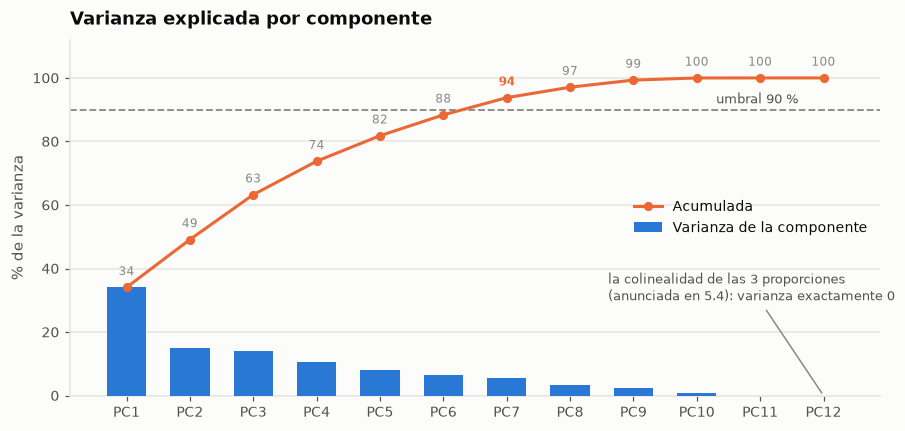

N_COMP = 7 componentes → varianza acumulada 93.8 %  ·  X_pca: (3781, 7)


In [41]:
from sklearn.decomposition import PCA

pca_full = PCA(random_state=SEED).fit(X_esc)
evr = 100 * pca_full.explained_variance_ratio_
acum = evr.cumsum()
N_COMP = int(np.argmax(acum >= 90) + 1)

fig, ax = plt.subplots(figsize=(9.5, 4.2))
x = np.arange(1, len(evr) + 1)
ax.bar(x, evr, color=AZUL, width=0.62, zorder=3, label='Varianza de la componente')
ax.plot(x, acum, color=NARANJA, marker='o', ms=5, zorder=4, label='Acumulada')
ax.axhline(90, color=TINTA3, ls='--', lw=1.2, zorder=2)
ax.text(11.6, 92, 'umbral 90 %', fontsize=8.5, color=TINTA2, ha='right')
for xi, v in zip(x, acum):
    ax.annotate(f'{v:.0f}', (xi, v), textcoords='offset points', xytext=(0, 8),
                ha='center', fontsize=8, color=NARANJA if xi == N_COMP else TINTA3,
                fontweight='bold' if xi == N_COMP else 'normal')
ax.annotate('la colinealidad de las 3 proporciones\n(anunciada en 5.4): varianza exactamente 0',
            xy=(12, evr[-1]), xytext=(8.6, 30), fontsize=8.5, color=TINTA2,
            arrowprops=dict(arrowstyle='-', color=TINTA3, lw=1))
ax.set_xticks(x, [f'PC{i}' for i in x])
ax.set_ylim(0, 112)
ax.grid(axis='y', zorder=0)
ax.set_title('Varianza explicada por componente')
ax.set_ylabel('% de la varianza')
ax.legend(loc='center right')
fig.savefig(FIG / 'e8_varianza.png'); plt.show()

pca = PCA(n_components=N_COMP, random_state=SEED)
X_pca = pca.fit_transform(X_esc)
print(f'N_COMP = {N_COMP} componentes → varianza acumulada {acum[N_COMP - 1]:.1f} %'
      f'  ·  X_pca: {X_pca.shape}')

**Lectura de la gráfica:** con **7 componentes se retiene el 93,8 %** de la varianza — de 12 columnas a 7 dimensiones sin perder casi información. Los dos extremos de la curva confirman diagnósticos previos: PC1 sola captura el 34 % (el gran bloque correlacionado del 5.4) y **PC12 tiene varianza exactamente 0** (7,4×10⁻¹⁷): es la dimensión fantasma creada por `prop_lun_mie + prop_jue_vie + prop_dom = 1`. El PCA la elimina de forma natural — no hizo falta borrar ninguna proporción a mano.

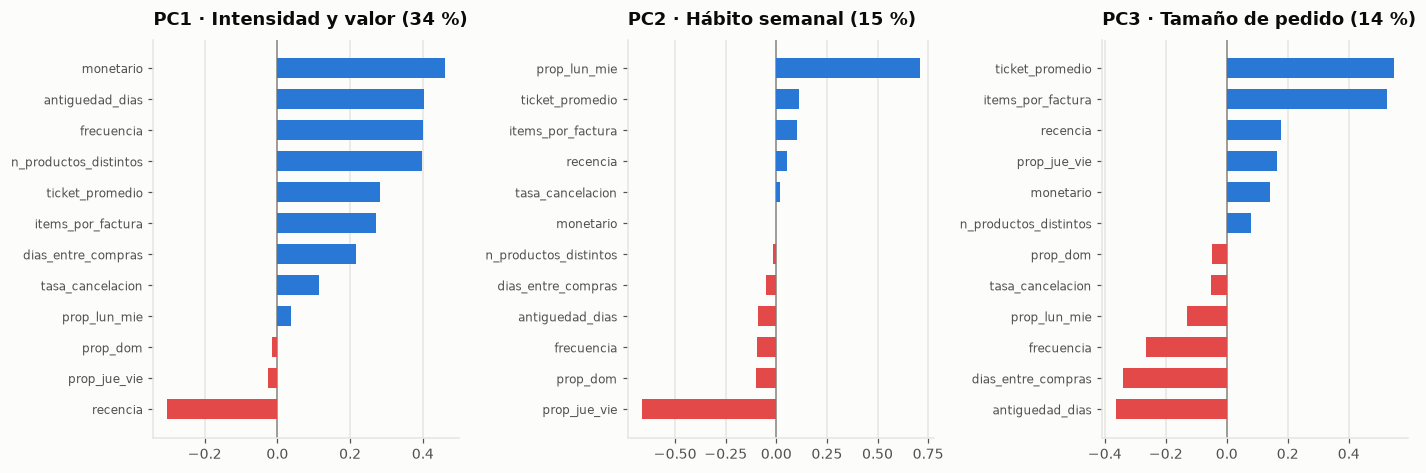

In [42]:
cargas = pd.DataFrame(pca.components_[:3].T, index=X_esc.columns,
                      columns=['PC1', 'PC2', 'PC3'])

fig, axes = plt.subplots(1, 3, figsize=(13, 4.4))
for ax, pc, nombre in [(axes[0], 'PC1', f'PC1 · Intensidad y valor ({evr[0]:.0f} %)'),
                       (axes[1], 'PC2', f'PC2 · Hábito semanal ({evr[1]:.0f} %)'),
                       (axes[2], 'PC3', f'PC3 · Tamaño de pedido ({evr[2]:.0f} %)')]:
    v = cargas[pc].sort_values()
    ax.barh(range(len(v)), v, color=[ROJO if c < 0 else AZUL for c in v],
            height=0.65, zorder=3)
    ax.set_yticks(range(len(v)), v.index, fontsize=8)
    ax.axvline(0, color=TINTA3, lw=1, zorder=2)
    ax.grid(axis='x', zorder=0)
    ax.set_title(nombre)
fig.tight_layout()
fig.savefig(FIG / 'e8_cargas.png'); plt.show()

**Lectura de la gráfica — qué significa cada eje:**

- **PC1 (34 %) — intensidad y valor de la relación:** cargan juntas `monetario` (+0,46), `antiguedad_dias` (+0,40), `frecuencia` (+0,40) y `n_productos_distintos` (+0,40), con `recencia` en contra (−0,30). Es el eje RFM condensado: a la derecha, clientes valiosos y activos; a la izquierda, chicos y fríos.
- **PC2 (15 %) — hábito semanal:** `prop_lun_mie` (+0,71) contra `prop_jue_vie` (−0,67). Un eje puramente conductual, ortogonal al valor — la variación "aparte" que el 5.4 ya mostraba.
- **PC3 (14 %) — tamaño de pedido:** `ticket_promedio` (+0,55) e `items_por_factura` (+0,52) contra `antiguedad_dias` (−0,36) y `dias_entre_compras` (−0,34): cestas grandes y concentradas frente a veteranos de pedidos pequeños y espaciados. Las **dos estrategias mayoristas** que la correlación del 5.4 insinuaba.

Los tres ejes son interpretables — requisito para poder explicar los clústeres en términos de negocio en el paso 12.

---
# 9. Elección de k: los cuatro criterios de la guía

Codo (inercia), Calinski-Harabasz, silueta y dendrograma Ward, todos sobre `X_pca` y con `random_state=42`. Ningún criterio manda por sí solo: si discrepan, se explica la discrepancia y decide la accionabilidad de negocio.

,Inercia,Calinski-Harabasz,Silueta
k,,,
2,"31,418.95","1,338.88",0.25
3,"26,553.64","1,137.99",0.27
4,"23,979.72",975.02,0.23
5,"22,387.06",850.24,0.20
6,"18,587.38",973.36,0.26
7,"17,495.29",900.80,0.23
8,"16,307.93",867.36,0.24
9,"15,390.70",832.06,0.23
10,"14,595.12",802.55,0.22


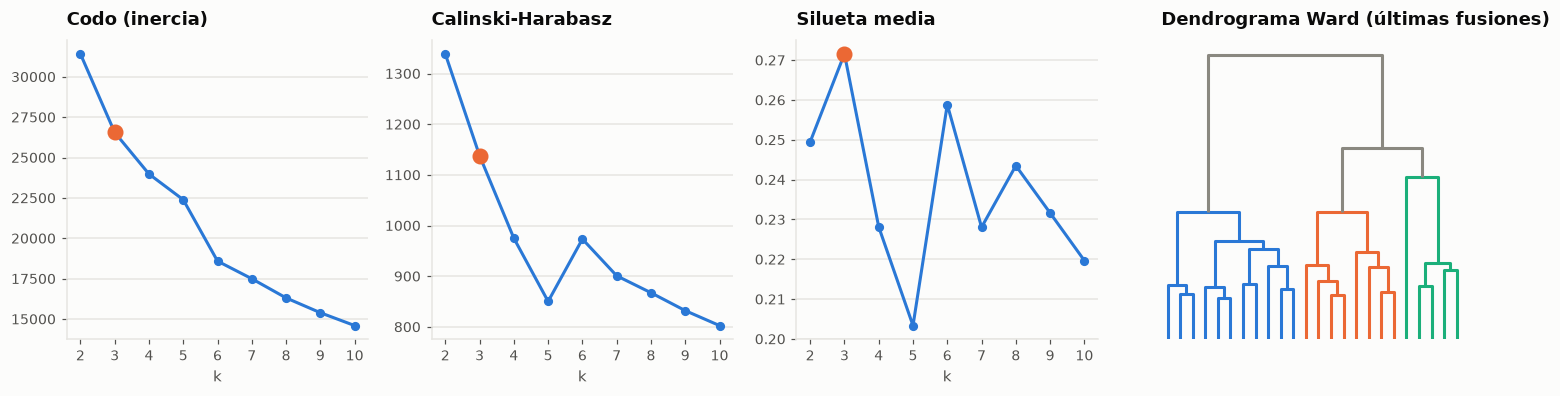

Alturas de las últimas 5 fusiones Ward: [ 63.9  64.1  81.6  96.2 143.4]


In [43]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import linkage, dendrogram, set_link_color_palette

res = []
for k in range(2, 11):
    km_k = KMeans(n_clusters=k, n_init='auto', random_state=SEED).fit(X_pca)
    res.append({'k': k, 'Inercia': km_k.inertia_,
                'Calinski-Harabasz': calinski_harabasz_score(X_pca, km_k.labels_),
                'Silueta': silhouette_score(X_pca, km_k.labels_)})
criterios = pd.DataFrame(res).set_index('k')
display(criterios.round(3))

Z = linkage(X_pca, method='ward')

fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.7))
ks = criterios.index
for ax, col, titulo in [(axes[0], 'Inercia', 'Codo (inercia)'),
                        (axes[1], 'Calinski-Harabasz', 'Calinski-Harabasz'),
                        (axes[2], 'Silueta', 'Silueta media')]:
    ax.plot(ks, criterios[col], color=AZUL, marker='o', ms=5, zorder=3)
    mejor = criterios[col].idxmax() if col != 'Inercia' else 3
    ax.scatter([3], [criterios.loc[3, col]], s=90, color=NARANJA, zorder=4)
    ax.set_xticks(ks)
    ax.grid(axis='y', zorder=0)
    ax.set_title(titulo)
    ax.set_xlabel('k')

set_link_color_palette([AZUL, NARANJA, AQUA, VIOLETA])
dendrogram(Z, ax=axes[3], truncate_mode='lastp', p=24, no_labels=True,
           color_threshold=90, above_threshold_color=TINTA3)
axes[3].set_title('Dendrograma Ward (últimas fusiones)')
axes[3].set_yticks([])
for lado in axes[3].spines.values():
    lado.set_visible(False)
fig.tight_layout()
fig.savefig(FIG / 'e9_criterios.png'); plt.show()

print('Alturas de las últimas 5 fusiones Ward:', np.round(Z[-5:, 2], 1))

**Lectura de la gráfica — los criterios discrepan, y la discrepancia es informativa:**

| Criterio | Sugiere | Por qué |
|---|---|---|
| Calinski-Harabasz | k=2 (1.339) | Premia la separación gruesa: recurrentes vs compradores únicos |
| Dendrograma | k=2 (salto de 96 → 143); después k=4 y k=3 | La primera división es la misma frontera gruesa |
| Silueta | **k=3 (0,272)**, máximo local en k=6 (0,259) | El mejor equilibrio cohesión/separación |
| Codo | k=3–4 (mayor caída relativa en 2→3: 15,5 %; eco en 5→6) | Ganancia marginal decreciente después de 3 |

**Decisión: k=3.** k=2 es estadísticamente cómodo pero trivial para el negocio (dos mitades sin acción diferenciada); k=6 fragmenta sin superar la silueta de k=3 (0,259 < 0,272). k=3 tiene la mejor silueta, el segundo mejor CH, coincide con la mayor caída del codo y con el tercer salto del dendrograma, y produce tres segmentos de tamaños manejables (1.803 / 999 / 979).

---
# 10. Clustering: tres algoritmos compiten

Con k=3 decidido, la guía exige comparar **al menos dos algoritmos**. Se enfrentan K-Means, Aglomerativo Ward (coherente con el dendrograma del paso 9) y DBSCAN — con la regla de oro de este último: **la etiqueta −1 es ruido, no un clúster**.

In [44]:
from sklearn.cluster import DBSCAN, AgglomerativeClustering

K_FINAL = 3

km = KMeans(n_clusters=K_FINAL, n_init='auto', random_state=SEED).fit(X_pca)
ward = AgglomerativeClustering(n_clusters=K_FINAL).fit(X_pca)

# --- DBSCAN: barrido de eps con min_samples = dimensiones + 1 ---------------
filas = []
for eps in np.arange(0.4, 3.01, 0.2):
    et = DBSCAN(eps=eps, min_samples=X_pca.shape[1] + 1).fit_predict(X_pca)
    nc = len(set(et)) - (1 if -1 in et else 0)
    sin_ruido = et != -1                       # -1 = RUIDO, nunca un clúster
    sil = (silhouette_score(X_pca[sin_ruido], et[sin_ruido]) if nc >= 2 else np.nan)
    filas.append({'eps': round(eps, 1), 'Clústeres': nc,
                  '% ruido': 100 * (~sin_ruido).mean(),
                  'Silueta (sin ruido)': sil})
display(pd.DataFrame(filas).set_index('eps').round(3))

et_db = DBSCAN(eps=1.4, min_samples=X_pca.shape[1] + 1).fit_predict(X_pca)
m_db = et_db != -1
sil_db = silhouette_score(X_pca[m_db], et_db[m_db])

comparativa = pd.DataFrame([
    ['K-Means (k=3)', silhouette_score(X_pca, km.labels_),
     ' / '.join(miles(v) for v in np.bincount(km.labels_)), '0 %'],
    ['Aglomerativo Ward (k=3)', silhouette_score(X_pca, ward.labels_),
     ' / '.join(miles(v) for v in np.bincount(ward.labels_)), '0 %'],
    ['DBSCAN (eps=1,4 · min_samples=8)', sil_db,
     ' / '.join(miles(v) for v in np.bincount(et_db[m_db])),
     f'{100 * (~m_db).mean():.1f} %'],
], columns=['Modelo', 'Silueta', 'Tamaños', 'Ruido']).set_index('Modelo')
display(comparativa.round(3))

cruce = pd.crosstab(km.labels_, ward.labels_)
coincide = cruce.values[np.arange(K_FINAL), cruce.values.argmax(axis=1)].sum()
print(f'Acuerdo K-Means vs Ward (mejor mapeo): {miles(coincide)} de '
      f'{miles(len(X_pca))} clientes = {100 * coincide / len(X_pca):.1f} %')

# --- Modelo final: K-Means; etiquetas C0..C2 por monetario mediano desc -----
etq = pd.Series(km.labels_, index=clientes_clean.index)
orden = (clientes_clean.groupby(etq)['monetario'].median()
         .sort_values(ascending=False).index)
clientes_clean['Cluster'] = etq.map({v: f'C{i}' for i, v in enumerate(orden)})
clientes_clean.groupby('Cluster').size()

,Clústeres,% ruido,Silueta (sin ruido)
eps,,,
0.40,8,78.71,0.37
0.60,17,64.98,0.19
0.80,18,44.56,0.12
1.00,10,22.80,-0.03
1.20,5,10.34,-0.03
1.40,4,4.29,0.08
1.60,1,1.64,NaN
1.80,1,0.71,NaN
2.00,1,0.45,NaN


,Silueta,Tamaños,Ruido
Modelo,,,
K-Means (k=3),0.27,999 / 1.803 / 979,0 %
Aglomerativo Ward (k=3),0.27,777 / 1.974 / 1.030,0 %
"DBSCAN (eps=1,4 · min_samples=8)",0.08,3.385 / 163 / 64 / 7,4.3 %


Acuerdo K-Means vs Ward (mejor mapeo): 3.441 de 3.781 clientes = 91.0 %


Cluster
C0    1803
C1     979
C2     999
dtype: int64

**Lectura de la comparación:**

- **DBSCAN se descarta con diagnóstico, no por capricho.** El barrido muestra el dilema completo: con eps=0,4 logra silueta 0,37 pero declara **ruido al 78,7 %** de los clientes; con eps=1,4 el ruido baja a 4,3 % pero produce un megaclúster de 3.385 clientes (silueta 0,08); desde eps=1,6 colapsa a un solo clúster. Es el comportamiento típico de features RFM **continuas**: no hay valles de densidad que separar. Su aporte real es confirmar que la estructura es de *gradiente*, no de islas.
- **K-Means y Ward encuentran lo mismo** (acuerdo del 91,0 % con el mejor mapeo): la partición no es un artefacto del algoritmo.
- **Ganador: K-Means** — silueta 0,272 vs 0,265, tamaños más equilibrados (1.803/999/979 vs 1.974/1.030/777) y centroides directamente interpretables.

Las etiquetas finales se renombran **C0, C1, C2 en orden descendente de monetario mediano** para que la lectura de negocio sea inmediata.

---
# 11. Validación visual: PCA y t-SNE

Doble chequeo visual de la partición. El t-SNE se calcula **solo para visualizar** (nunca como entrada del modelo): si los colores — asignados por K-Means en el espacio PCA de 7 dimensiones — aparecen separados también en el mapa t-SNE, la estructura es real y no un accidente de la proyección.

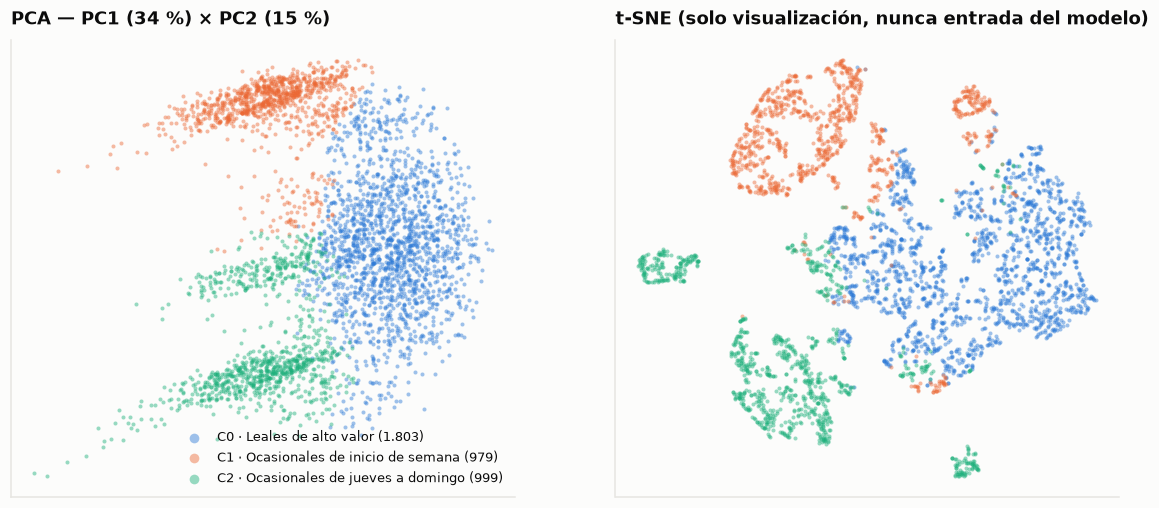

Silueta de las etiquetas finales: 0.272 en el espacio PCA → 0.365 medida en el espacio t-SNE


In [45]:
from sklearn.manifold import TSNE

X_tsne = TSNE(n_components=2, random_state=SEED, perplexity=30,
              init='pca').fit_transform(X_pca)

COL_CLUSTER = {'C0': AZUL, 'C1': NARANJA, 'C2': AQUA}
NOMBRES = {'C0': 'Leales de alto valor',
           'C1': 'Ocasionales de inicio de semana',
           'C2': 'Ocasionales de jueves a domingo'}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, XY, titulo in [
        (axes[0], X_pca[:, :2], f'PCA — PC1 ({evr[0]:.0f} %) × PC2 ({evr[1]:.0f} %)'),
        (axes[1], X_tsne, 't-SNE (solo visualización, nunca entrada del modelo)')]:
    for c in COL_CLUSTER:
        m = (clientes_clean['Cluster'] == c).values
        ax.scatter(XY[m, 0], XY[m, 1], s=7, color=COL_CLUSTER[c], alpha=0.45,
                   lw=0, zorder=3, label=f'{c} · {NOMBRES[c]} ({miles(m.sum())})')
    ax.set_title(titulo)
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(loc='lower right', markerscale=2.4, fontsize=8.5)
fig.savefig(FIG / 'e11_validacion.png'); plt.show()

sil_tsne = silhouette_score(X_tsne, clientes_clean['Cluster'])
sil_pca = silhouette_score(X_pca, clientes_clean['Cluster'])
print(f'Silueta de las etiquetas finales: {sil_pca:.3f} en el espacio PCA '
      f'→ {sil_tsne:.3f} medida en el espacio t-SNE')

**Lectura de la gráfica:** los dos paneles cuentan la misma historia desde ángulos distintos:

- En **PCA**, C1 (naranja) y C2 (aqua) se separan verticalmente — PC2 es el eje de *hábito semanal* — y C0 (azul) se extiende hacia la derecha del eje PC1 (*intensidad y valor*).
- En **t-SNE**, que no vio jamás las etiquetas, los tres grupos aparecen como regiones coherentes: C1 y C2 como bloques compactos y C0 como una región amplia. La silueta de las etiquetas *sube* de 0,272 (espacio PCA) a **0,365** en el mapa t-SNE: la estructura sobrevive a una proyección no lineal independiente — el clustering es coherente.

Que C0 sea una región amplia y continua (y no una isla) es consistente con el diagnóstico de DBSCAN: dentro de los leales el valor es un **gradiente**, no hay subgrupos densos separados.

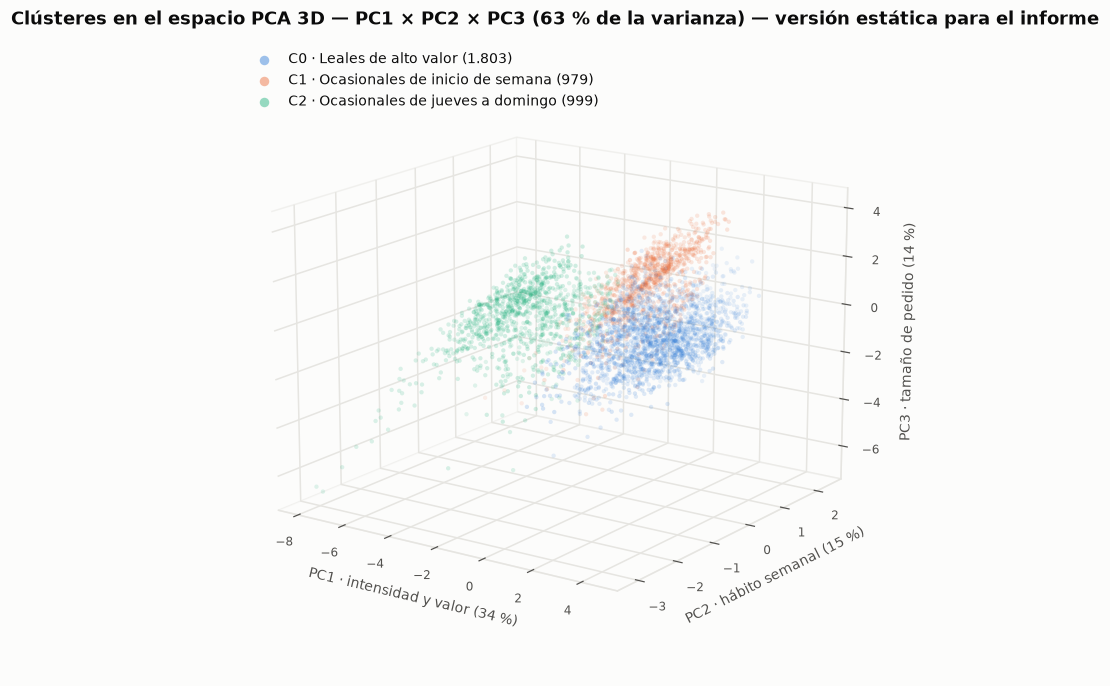

In [46]:
fig = plt.figure(figsize=(10.5, 7.5))
ax = fig.add_subplot(projection='3d')
for c in COL_CLUSTER:
    m = (clientes_clean['Cluster'] == c).values
    ax.scatter(X_pca[m, 0], X_pca[m, 1], X_pca[m, 2], s=8, color=COL_CLUSTER[c],
               alpha=0.45, lw=0, label=f'{c} · {NOMBRES[c]} ({miles(m.sum())})')
ax.set_xlabel(f'PC1 · intensidad y valor ({evr[0]:.0f} %)', fontsize=9)
ax.set_ylabel(f'PC2 · hábito semanal ({evr[1]:.0f} %)', fontsize=9)
ax.set_zlabel(f'PC3 · tamaño de pedido ({evr[2]:.0f} %)', fontsize=9)
ax.view_init(elev=16, azim=-55)
ax.tick_params(labelsize=8)
for eje in [ax.xaxis, ax.yaxis, ax.zaxis]:
    eje.pane.set_facecolor(SUP)
    eje.pane.set_edgecolor(REJILLA)
ax.set_title(f'Clústeres en el espacio PCA 3D — PC1 × PC2 × PC3 '
             f'({evr[:3].sum():.0f} % de la varianza) — versión estática para el informe')
ax.legend(loc='upper left', markerscale=2.2, fontsize=9)
fig.savefig(FIG / 'e11_pca3d.png'); plt.show()

In [47]:
import plotly.express as px

df3d = pd.DataFrame(X_pca[:, :3], columns=['PC1', 'PC2', 'PC3'],
                    index=clientes_clean.index)
df3d['Segmento'] = clientes_clean['Cluster'].map(lambda c: f'{c} · {NOMBRES[c]}')

fig3d = px.scatter_3d(
    df3d, x='PC1', y='PC2', z='PC3', color='Segmento',
    color_discrete_map={f'{c} · {NOMBRES[c]}': COL_CLUSTER[c] for c in COL_CLUSTER},
    category_orders={'Segmento': [f'{c} · {NOMBRES[c]}' for c in COL_CLUSTER]},
    opacity=0.6,
    title='Visualización 3D de los clústeres, en el espacio de componentes principales (Plotly)')
fig3d.update_traces(marker_size=3)
fig3d.update_layout(
    template='plotly_white', width=950, height=680,
    font=dict(family='Segoe UI', color=TINTA),
    scene=dict(xaxis_title=f'PC1 · intensidad y valor ({evr[0]:.0f} %)',
               yaxis_title=f'PC2 · hábito semanal ({evr[1]:.0f} %)',
               zaxis_title=f'PC3 · tamaño de pedido ({evr[2]:.0f} %)'))
fig3d.show()

**Lectura de la gráfica 3D** (la versión Plotly es interactiva: rota, filtra por segmento con la leyenda y haz zoom)**:** los tres ejes nombrados en el paso 8 trabajan en vivo: **PC1** (intensidad y valor) separa a los Leales (azul, hacia la derecha) de los dos grupos ocasionales; **PC2** (hábito semanal) separa a C1 (naranja, arriba) de C2 (aqua, abajo); y **PC3** (tamaño de pedido) muestra que dentro de cada grupo conviven cestas grandes y chicas — la dimensión que el clustering *no* usó para separar, coherente con que C1 y C2 sean gemelos en valor. La vista 3D confirma lo del plano: grupos contiguos sobre un gradiente, sin islas.

---
# 12. Interpretación de negocio

Un clúster sin nombre ni acción no sirve. Se perfila cada segmento con medianas (colas mandan), se mide su peso en clientes **y en dinero**, y se le asigna nombre y acción. Los 553 atípicos del paso 6 se reincorporan aquí como cuarto segmento de gestión individual.

In [48]:
grp = clientes_clean.groupby('Cluster')

CLAVE = ['recencia', 'frecuencia', 'monetario', 'ticket_promedio',
         'items_por_factura', 'n_productos_distintos', 'tasa_cancelacion',
         'antiguedad_dias']
perfil = grp[CLAVE].median().round(2)
perfil.insert(0, 'Clientes', grp.size())
perfil.insert(1, '% de la base (4.334)', (100 * grp.size() / len(clientes_df)).round(1))
perfil['prop_lun_mie (media)'] = grp['prop_lun_mie'].mean().round(2)
perfil['prop_jue_vie (media)'] = grp['prop_jue_vie'].mean().round(2)
perfil['prop_dom (media)'] = grp['prop_dom'].mean().round(2)
perfil['% con 1 sola compra'] = grp['frecuencia'].apply(lambda s: 100 * (s == 1).mean()).round(1)
perfil['% £ del total'] = (100 * grp['monetario'].sum()
                           / clientes_df['monetario'].sum()).round(1)
display(perfil.T)

print(f"El cuarto segmento — Atípicos (paso 6): {len(atipicos)} clientes "
      f"({100 * len(atipicos) / len(clientes_df):.1f} % de la base) con el "
      f"{100 * atipicos['monetario'].sum() / clientes_df['monetario'].sum():.1f} % "
      f"del monetario total")

Cluster,C0,C1,C2
Clientes,"1,803.00",979.00,999.00
% de la base (4.334),41.60,22.60,23.10
recencia,25.00,116.00,120.00
frecuencia,4.00,1.00,1.00
monetario,"1,336.43",297.78,288.42
ticket_promedio,306.86,219.52,207.28
items_por_factura,180.00,129.00,114.00
n_productos_distintos,64.00,17.00,18.00
tasa_cancelacion,0.00,0.00,0.00
antiguedad_dias,235.00,0.00,0.00


El cuarto segmento — Atípicos (paso 6): 553 clientes (12.8 % de la base) con el 53.8 % del monetario total


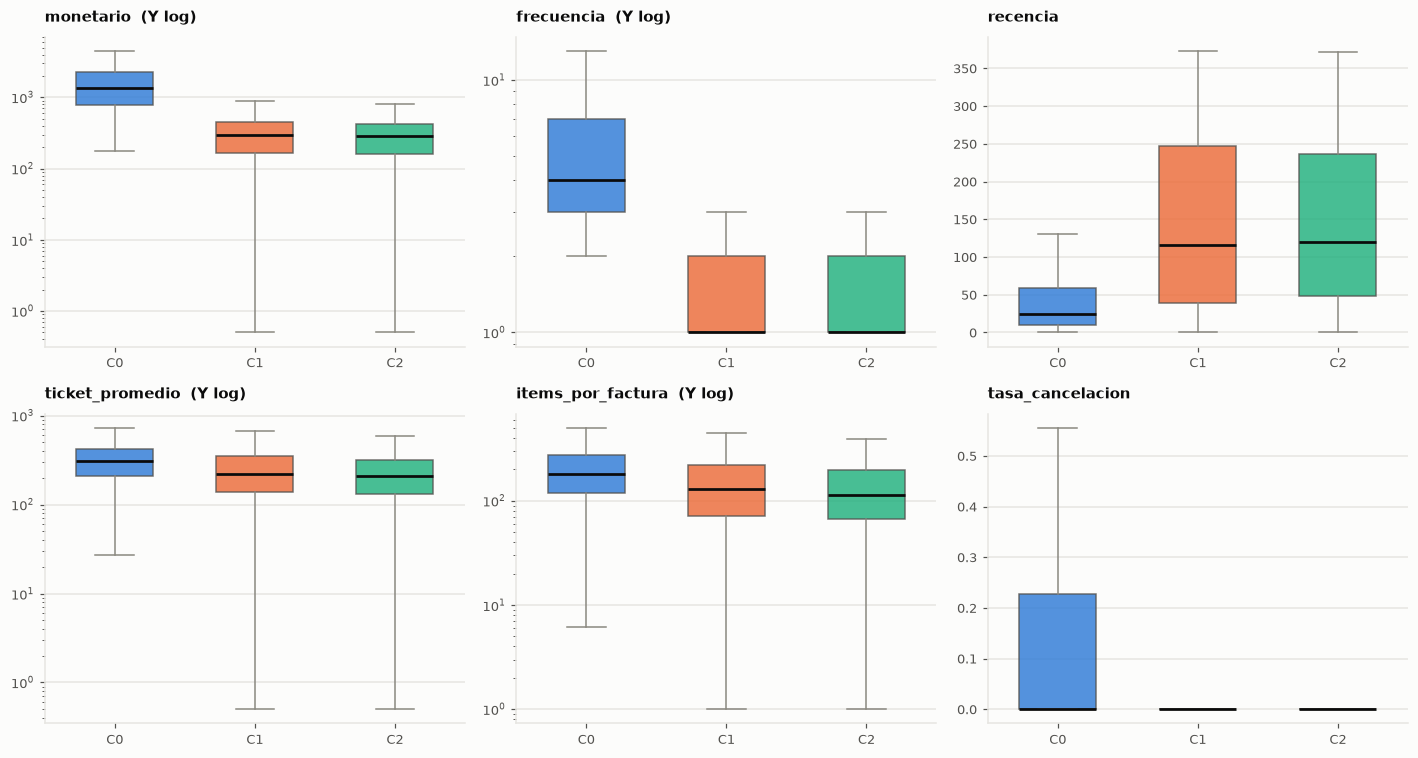

In [49]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
PANELES = [('monetario', True), ('frecuencia', True), ('recencia', False),
           ('ticket_promedio', True), ('items_por_factura', True),
           ('tasa_cancelacion', False)]
for ax, (col, logy) in zip(axes.flat, PANELES):
    datos = [clientes_clean.loc[clientes_clean['Cluster'] == c, col] for c in COL_CLUSTER]
    if logy:
        datos = [d.clip(lower=0.5) for d in datos]
    bp = ax.boxplot(datos, patch_artist=True, showfliers=False, widths=0.55,
                    medianprops=dict(color=TINTA, lw=1.8))
    for caja, c in zip(bp['boxes'], COL_CLUSTER):
        caja.set_facecolor(COL_CLUSTER[c])
        caja.set_alpha(0.8)
        caja.set_edgecolor(TINTA2)
    for parte in ['whiskers', 'caps']:
        for linea in bp[parte]:
            linea.set_color(TINTA3)
    if logy:
        ax.set_yscale('log')
    ax.set_xticks([1, 2, 3], list(COL_CLUSTER))
    ax.set_title(col + ('  (Y log)' if logy else ''), fontsize=10)
    ax.grid(axis='y', zorder=0)
    ax.tick_params(labelsize=8.5)
fig.tight_layout()
fig.savefig(FIG / 'e12_boxplots.png'); plt.show()

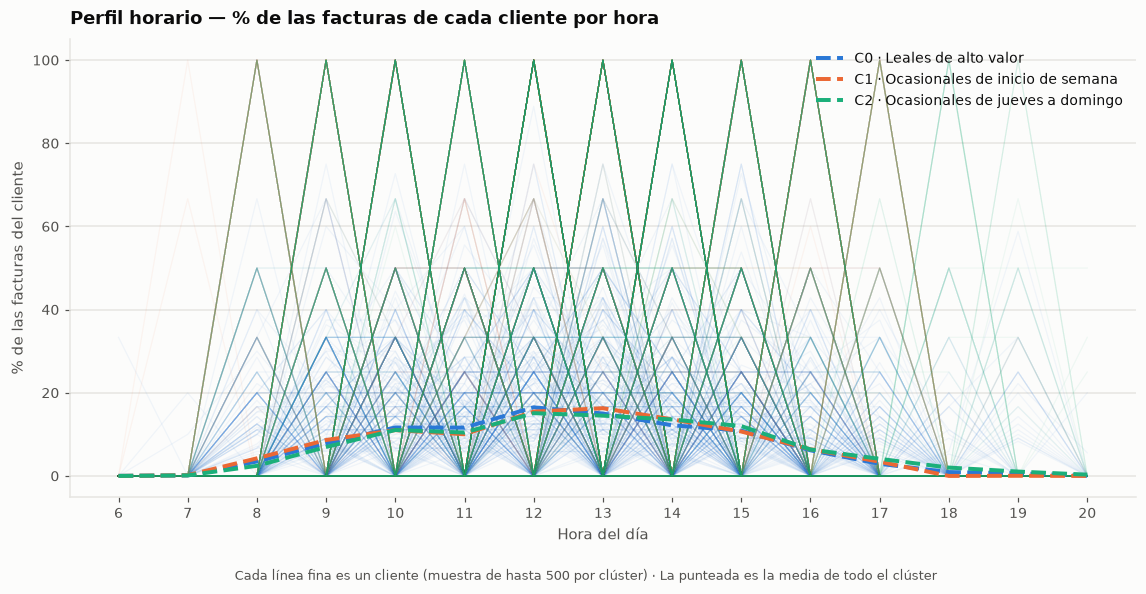

In [50]:
fact_cli = fact[fact['IdCliente'].isin(clientes_clean.index)].copy()

HORAS = list(range(6, 21))
perfil_hora = (100 * pd.crosstab(fact_cli['IdCliente'], fact_cli['Hora'],
                                 normalize='index')).reindex(columns=HORAS, fill_value=0)
perfil_dia = (100 * pd.crosstab(fact_cli['IdCliente'], fact_cli['Dia'],
                                normalize='index')).reindex(
                                    columns=list(ETIQ_DIA.values()), fill_value=0)

# Muestra balanceada: hasta 500 clientes por clúster, para que las tres
# nubes de líneas se vean con densidad comparable (C0 triplica a C1/C2)
rng = np.random.default_rng(SEED)
muestra = {c: rng.choice(np.asarray(clientes_clean.index[(clientes_clean['Cluster'] == c).values]),
                         size=min(500, (clientes_clean['Cluster'] == c).sum()), replace=False)
           for c in COL_CLUSTER}

def perfil_espagueti(perfil, etiquetas, titulo, xlabel, archivo):
    fig, ax = plt.subplots(figsize=(12.5, 5.4))
    x = np.arange(perfil.shape[1])
    for c in COL_CLUSTER:                       # cada línea fina = un cliente
        ax.plot(x, perfil.loc[muestra[c]].T.values, color=COL_CLUSTER[c],
                alpha=0.06, lw=0.8, zorder=2)
    for c in COL_CLUSTER:                       # punteada = media de TODO el clúster
        idx = clientes_clean.index[(clientes_clean['Cluster'] == c).values]
        ax.plot(x, perfil.loc[idx].mean().values, color=COL_CLUSTER[c], ls='--',
                lw=2.6, zorder=4, label=f'{c} · {NOMBRES[c]}')
    ax.set_xticks(x, etiquetas)
    ax.grid(axis='y', zorder=0)
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('% de las facturas del cliente')
    ax.legend(loc='upper right', fontsize=9)
    fig.text(0.5, -0.03, 'Cada línea fina es un cliente (muestra de hasta 500 por clúster) · '
             'La punteada es la media de todo el clúster', ha='center',
             fontsize=8.5, color=TINTA2)
    fig.savefig(FIG / archivo); plt.show()

perfil_espagueti(perfil_hora, [str(h) for h in HORAS],
                 'Perfil horario — % de las facturas de cada cliente por hora',
                 'Hora del día', 'e12_perfil_hora.png')

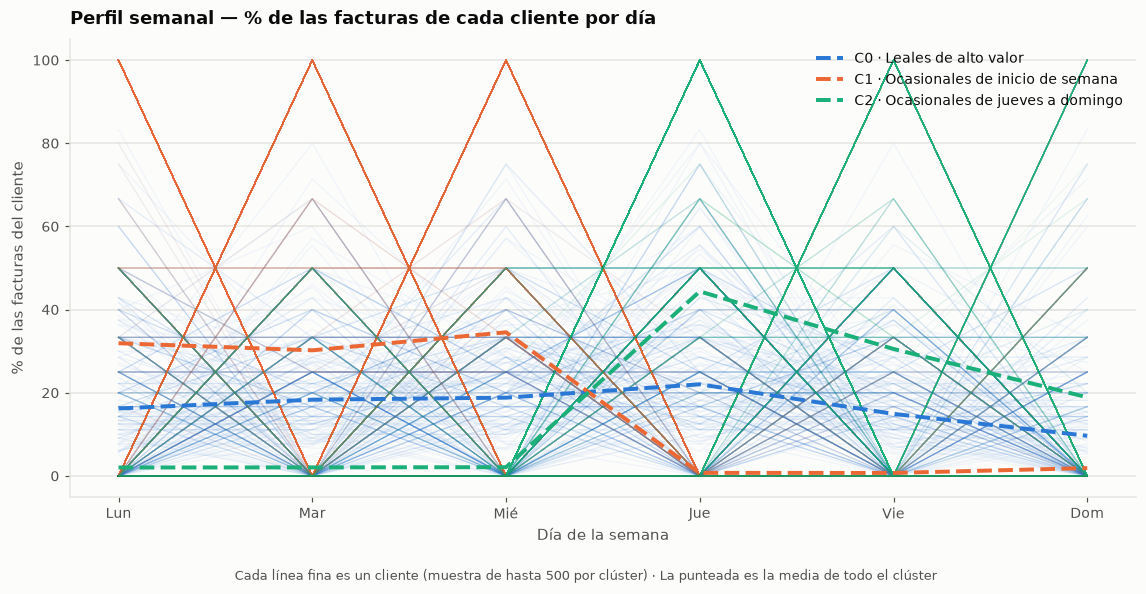

In [51]:
perfil_espagueti(perfil_dia, [d[:3] for d in ETIQ_DIA.values()],
                 'Perfil semanal — % de las facturas de cada cliente por día',
                 'Día de la semana', 'e12_perfil_semana.png')

**Lectura de las dos gráficas** (cada línea fina es un cliente; la punteada, el perfil medio de su clúster; la muestra de líneas está balanceada a 500 clientes por clúster para que las tres nubes se comparen en igualdad):

- **Perfil horario:** las tres nubes y las tres medias se superponen — pico al mediodía, actividad 8–17 h. **El hábito que separa a los clústeres no está en la hora**: ningún grupo madruga ni trasnocha más que otro.
- **Perfil semanal:** aquí las nubes se parten en dos mitades de la semana y se ve al algoritmo trabajando sobre el eje PC2: **la nube naranja (C1) solo tiene picos de lunes a miércoles** y **la aqua (C2) solo de jueves a domingo**, mientras la azul (C0) reparte sus facturas de forma pareja — el patrón plano del cliente recurrente. Las líneas que llegan al 100 % son clientes que concentran todas sus compras en un único día de la semana: el "hábito fijo" cuantificado en el paso 3.

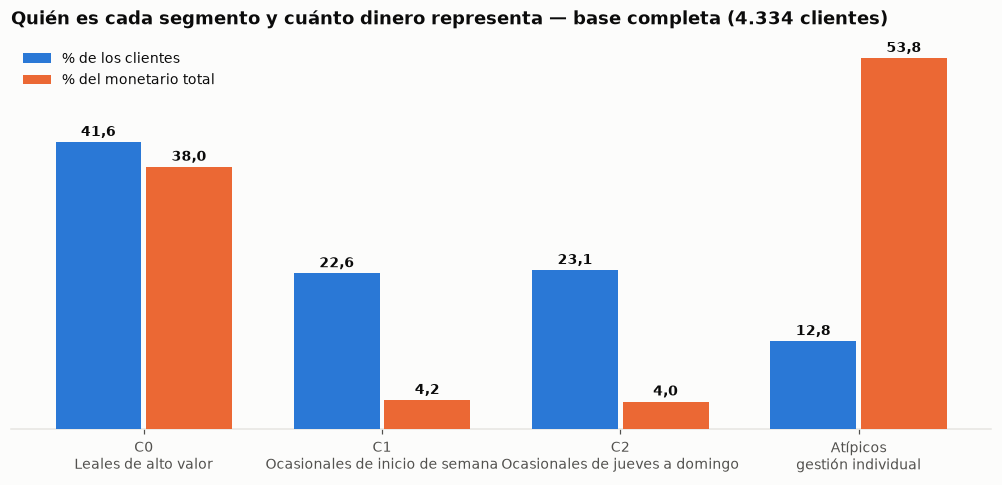

In [52]:
seg = pd.DataFrame({
    '% de los clientes': list(100 * grp.size() / len(clientes_df))
                         + [100 * len(atipicos) / len(clientes_df)],
    '% del monetario total': list(100 * grp['monetario'].sum()
                                  / clientes_df['monetario'].sum())
                             + [100 * atipicos['monetario'].sum()
                                / clientes_df['monetario'].sum()],
}, index=[f'{c} · {NOMBRES[c]}' for c in grp.size().index]
   + ['Atípicos · gestión individual'])

fig, ax = plt.subplots(figsize=(11.5, 4.6))
x = np.arange(len(seg))
ax.bar(x - 0.19, seg['% de los clientes'], 0.36, color=AZUL, zorder=3,
       label='% de los clientes')
ax.bar(x + 0.19, seg['% del monetario total'], 0.36, color=NARANJA, zorder=3,
       label='% del monetario total')
for xi, (a, b) in enumerate(zip(seg['% de los clientes'],
                                seg['% del monetario total'])):
    for dx, v in [(-0.19, a), (0.19, b)]:
        ax.annotate(f'{v:.1f}'.replace('.', ','), (xi + dx, v), xytext=(0, 4),
                    textcoords='offset points', ha='center', fontsize=9,
                    color=TINTA, fontweight='bold')
ax.set_xticks(x, [n.replace(' · ', chr(10)) for n in seg.index], fontsize=9)
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_title('Quién es cada segmento y cuánto dinero representa — base completa (4.334 clientes)')
ax.legend(loc='upper left')
fig.savefig(FIG / 'e12_segmentos.png'); plt.show()

**Lectura de las gráficas — la tabla de segmentos, con nombre y acción:**

| Segmento | Tamaño | Perfil (medianas) | % £ total | Acción recomendada |
|---|---|---|---|---|
| **C0 · Leales de alto valor** | 1.803 (41,6 %) | Compró hace 25 días, 4 pedidos, £1.336 netos, 64 productos distintos, 235 días de relación, sin cancelaciones | **38,0 %** | Programa de fidelización B2B, atención prioritaria y *cross-sell* sobre su amplitud de surtido |
| **C1 · Ocasionales de inicio de semana** | 979 (22,6 %) | 1 compra (74 % una sola), £298, hace 116 días; compran lun–mié (97 % de sus facturas) | 4,2 % | Reactivación con incentivo a la segunda compra, enviada lunes por la mañana |
| **C2 · Ocasionales de jueves a domingo** | 999 (23,0 %) | 1 compra (68 % una sola), £288, hace 120 días; compran jue–vie (75 %) y domingo (19 %) | 4,0 % | Reactivación con oferta de fin de semana y recordatorio dominical |
| **Atípicos · gestión individual** | 553 (12,8 %) | Ballenas legítimas (14646, 18102, 12415…) + anómalos de comportamiento (12346, 16446, 17548) | **53,8 %** | *Key accounts* con gestor dedicado; los anómalos, a revisión operativa de devoluciones |

Dos lecturas honestas que el informe debe conservar:

1. **C1 y C2 son gemelos en valor** (£298 vs £288 de mediana): con k=3, el algoritmo separó primero *recurrentes vs ocasionales* y luego dividió a los ocasionales **por hábito semanal** (el eje PC2), no por valor. Para acciones de valor puro pueden tratarse como un único grupo "Ocasionales dormidos" (45,6 % de la base, 8,2 % del dinero); la división por día es útil justamente para **programar el momento** de la campaña de reactivación.
2. **La concentración es extrema:** el 54,4 % de la base (C0 + atípicos) genera el **91,8 %** del ingreso. La tienda es, ante todo, un negocio de retención mayorista.

## 12.1 Respuesta explícita a las preguntas guía

### PG1 — ¿Se pueden segmentar los clientes según transacciones y gasto?

**Sí.** La matriz de 12 features por cliente, depurada de atípicos, escalada y proyectada a 7 componentes, produce con K-Means (k=3, silueta 0,272, validada con Ward al 91 % de acuerdo y visualmente con t-SNE) tres segmentos accionables más una capa de atípicos: **Leales de alto valor** (41,6 % de la base, 38,0 % del dinero), dos grupos de **Ocasionales dormidos** diferenciados por hábito semanal (45,6 %, 8,2 %) y **Atípicos de gestión individual** (12,8 %, 53,8 %). La estructura del valor es de gradiente continuo — no hay "islas" de clientes (diagnóstico DBSCAN) — por lo que los cortes son operativos, no naturales: exactamente lo esperable en una base mayorista.

### PG2 — ¿Se pueden identificar transacciones anómalas?

**Sí.** Isolation Forest sobre las 19.773 facturas, con `contamination` elegido por barrido (0,02: el nivel que aún agrega facturas por encima del P95 y se detiene antes de la cola mayorista legítima), marca **396 facturas anómalas** que concentran el 24,3 % de las £. Incluyen los dos pedidos fantasma del año (n.º 1 y n.º 2: 80.995 y 74.215 unidades, cancelados a los minutos) y un núcleo duro de 198 mega-facturas sobre el P99. El 46,2 % de las anómalas pertenece al bloque **sin `IdCliente`** — invisible para cualquier análisis por cliente y una razón de peso para haber conservado ese 25 % de los datos en el paso 1.

### PG3 — ¿Se pueden identificar clientes atípicos?

**Sí.** Isolation Forest sobre la matriz de clientes marca **553 atípicos (12,8 %)** que concentran el 53,8 % del monetario. Son dos familias de negocio distintas: (1) **ballenas legítimas** — 14646 (£278.778, el n.º 1 global), 18102, 12415, 12748 (206 facturas) — que merecen gestión individual, y (2) **anómalos de comportamiento** — 12346 y 16446 (los pedidos fantasma, con neto ≈ £0 pero delatados por `items_por_factura` y `tasa_cancelacion`), 17548 (devolvió más de lo que compró) — que merecen revisión operativa. El RFM clásico no habría visto a la segunda familia: la extensión de features del paso 5 fue la diferencia.

## 12.2 Cierre del análisis: checklist de la guía

- [x] Columnas, variables y etiquetas en español
- [x] Matriz final: una fila por cliente, **sin NaN** (4.334 × 12)
- [x] Faltantes tratados y justificados (25 % sin ID → dos niveles de análisis)
- [x] Cancelaciones tratadas explícitamente (feature + gasto neto, nunca borradas a ciegas)
- [x] Escalado **antes** de todo algoritmo de distancias (log1p + StandardScaler)
- [x] Anomalías detectadas **antes** de escalar y clusterizar (Isolation Forest, 2 niveles)
- [x] `contamination` elegido por barrido justificado, no por defecto
- [x] PCA con varianza explicada reportada (7 comp. = 93,8 %) y cargas interpretadas
- [x] ≥ 2 métodos para elegir k, con la discrepancia explicada (k=3)
- [x] ≥ 2 algoritmos comparados (K-Means, Ward, DBSCAN) con silueta reportada
- [x] El −1 de DBSCAN tratado como ruido, no como clúster
- [x] Validación visual con PCA y t-SNE (t-SNE solo visualización)
- [x] Cada clúster con nombre e interpretación de negocio + acción
- [x] PG1, PG2 y PG3 respondidas explícitamente
- [x] `random_state=42` en todo

**Limitaciones para el informe:** (1) el 25 % de las transacciones sin `IdCliente` queda fuera del análisis por cliente — se cubrió a nivel transacción; (2) un solo año de datos: la estacionalidad sep–nov puede confundirse con crecimiento; (3) sesgo UK (85 % de las £); (4) silueta moderada (0,27): los segmentos son cortes operativos sobre un gradiente, no grupos naturalmente separados; (5) asociación ≠ causalidad: los perfiles describen, no explican.